# Livrable 2 : débruitage d'images avec un auto-encodeur convolutif

Groupe :
* Isrâ BOUDEMAGH
* Théophile NOEL
* Bruno RIECKENBERG
* Corentin ROMANO

## Objectif

Les images numérisées à la chaîne par TouNum sont de qualité variable : certaines sont **bruitées** (grain, parasites du capteur ou du scanner). Un bruit mal géré perturbe les algorithmes suivants du workflow : le classifieur photo / autre (livrable 1) et le réseau de captioning (livrable 3). Ce notebook construit l'étape **« prétraitement »** du workflow : un **auto-encodeur convolutif de débruitage** (TensorFlow / Keras) qui reçoit une photo bruitée RGB et renvoie une photo plus propre, de même taille.

```
 images numérisées ──► [ Livrable 1 : photo ou autre ? ] ──► [ Livrable 2 : débruitage ] ──► [ Livrable 3 : captioning ]
                              (déjà fait)                        (ce notebook)
```

## Plan du notebook

| Partie | Contenu |
|---|---|
| 1 | **Chargement des données** : nettoyage, sous-ensemble, découpage entraînement / test |
| 2 | **Le bruit et les exemples d'entraînement** : bruit mixte, patchs en pleine résolution, jeux de test à bruit fixe |
| 3 | **Mesurer la qualité** (MSE, PSNR, SSIM) et **référence : filtres de convolution classiques** |
| 4 | **Code TensorFlow + schéma** de l'auto-encodeur (U-Net résiduel) |
| 5 | **Fonction de perte** |
| 6 | **Algorithme d'optimisation** et callbacks |
| 7 | **Entraînement** et courbes d'erreur / PSNR (entraînement et test) |
| 8 | **Analyse biais / variance** |
| 9 | **Évaluation comparative** : version 2 contre version 1 et filtres classiques, selon le niveau de bruit |
| 10 | **Étude de cas** : autres types de bruit, impact sur le classifieur du livrable 1, images réelles |
| 11 | **Méthodes pour améliorer** le débruitage |
| 12 | **Intégration au workflow** : fonction réutilisable pour le livrable 3, publication sur le site de test |

### Fichiers utilisés et produits

Le notebook se lance depuis le dossier `Livrable2/` du projet, indépendamment des autres livrables.

| Dossier | Contenu |
|---|---|
| `dataset/` | images du livrable 2 (non versionné) |
| `../models/` | **le modèle est enregistré ici dès la fin de son entraînement** (`cae_saut_v2.keras` et son historique `.csv`), à côté de ceux du livrable 1 ; `cae_saut.keras` est la version 1, gardée pour comparaison |
| `../Test_photos/` | les douze images de test du projet, jamais vues à l'entraînement (partie 10c) |
| `images_bruitees/` | trois images réellement bruitées, pour l'essai final (partie 12) |
| `sorties/` | images produites par les démonstrations de la partie 12 |

> **Vocabulaire.** Comme dans le livrable 1, le jeu de **test** est le jeu de *validation* de Keras : il ne sert jamais à mettre à jour les poids, mais il sert à choisir l'époque d'arrêt (voir les limites en partie 8).


In [1]:
# Bibliothèques : TensorFlow / Keras pour les réseaux, NumPy pour les calculs, Pandas pour les tableaux de résultats,
# Matplotlib pour les graphiques, SciPy pour les filtres de convolution classiques (point de comparaison)
import os
import pathlib
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from scipy import ndimage

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow :", tf.__version__)
print("GPU détectés :", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791901651.157166   46348 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791901652.957909   46348 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.21.0
GPU détectés : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1791901654.351279   46348 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
# ----- Paramètres du notebook, regroupés ici pour pouvoir tout relancer avec d'autres valeurs -----
# Les variables d'environnement L2_* permettent de les changer sans modifier le code (test rapide, machine sans GPU).
SEED = 42                 # même graine que le livrable 1 : découpages reproductibles
IMG = 200                 # taille des images du protocole de test « 200 x 200 » (celui de la version 1)
PATCH = int(os.environ.get("L2_PATCH", 128))           # côté des patchs (morceaux d'image) vus à l'entraînement
BATCH = int(os.environ.get("L2_BATCH", 16))            # patchs par mise à jour des poids
PAS_PAR_EPOQUE = int(os.environ.get("L2_PAS", 250))    # mises à jour des poids par époque
EPOCHS = int(os.environ.get("L2_EPOCHS", 80))          # nombre maximal d'époques (l'EarlyStopping arrête avant)
MAX_IMAGES = int(os.environ.get("L2_MAX_IMAGES", 0))   # taille du sous-ensemble d'images utilisé (0 = tout le dataset)
RETRAIN = os.environ.get("L2_RETRAIN", "1") == "1"     # False : recharge le modèle déjà entraîné s'il existe

# Bruit d'entraînement : un type de bruit tiré au hasard pour chaque patch (débruitage « aveugle »)
SIGMA_MIN, SIGMA_MAX = 0.0, 0.30    # écart-type du bruit gaussien, sur des pixels entre 0 et 1 (0,1 ≈ 25 niveaux de gris)
PROBA_BRUITS = {"gaussien": 0.50, "speckle": 0.25, "poivre et sel": 0.25}
ECHELLE_MIN = 0.5                   # chaque image est réduite d'un facteur tiré entre ECHELLE_MIN et 1 avant la découpe

# Évaluation
SIGMA_EVAL = 0.15         # niveau de bruit fixe des jeux de test et des courbes
COTE_TEST = 256           # carrés découpés au centre des images de test, en pleine résolution
N_EVAL = 64               # nombre d'images de test « 200 x 200 » gardées en mémoire pour les comparaisons détaillées

MODELS_DIR = pathlib.Path("../models")      # dossier commun du projet, avec les modèles du livrable 1
MODELS_DIR.mkdir(exist_ok=True, parents=True)
NOM_MODELE = "cae_saut_v2"                  # le modèle de ce notebook : models/cae_saut_v2.keras
NOM_VERSION_1 = "cae_saut"                  # version 1, comparée en partie 9 si le fichier existe
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)        # graine Python / NumPy / TensorFlow
print(f"Patchs {PATCH}x{PATCH}, batchs de {BATCH}, {PAS_PAR_EPOQUE} pas par époque, {EPOCHS} époques au plus, "
      f"{'ré-entraînement' if RETRAIN else 'rechargement du modèle enregistré'}")

Patchs 128x128, batchs de 16, 250 pas par époque, 80 époques au plus, ré-entraînement


## 1. Chargement des données

Le dataset est un dossier d'images RGB. Le code ci-dessous cherche le dossier à plusieurs emplacements usuels
(`DATASET_CANDIDATS`) et parcourt **récursivement** tous les sous-dossiers : il n'y a donc pas besoin de modifier
le code si les images sont rangées par sous-dossiers. Ici les étiquettes de classe ne servent pas : la cible
d'un auto-encodeur de débruitage est **l'image propre elle-même**, c'est de l'apprentissage auto-supervisé.

Étapes :
1. **Listage et sous-ensemble** : on mélange la liste des fichiers avec la graine 42 puis on garde `MAX_IMAGES` images.
   C'est le « sous-ensemble » sur lequel on débruite ; il garde le temps d'entraînement raisonnable et se règle en une ligne.
2. **Nettoyage** : une seule image illisible ferait planter l'entraînement en pleine époque. On réutilise la logique du
   livrable 1 : ré-encodage en JPEG si Pillow sait lire l'image mais pas TensorFlow, sinon l'image est déplacée dans un dossier de rejets (rien n'est supprimé).
3. **Découpage 80 % / 20 %** : entraînement / test, aucune image n'est dans les deux.

> Si le dataset fourni contenait déjà des couples « bruité / propre » (deux dossiers), il suffirait de remplacer la
> fonction `paire_entrainement` de la partie 2 par une lecture des deux fichiers ; le reste du notebook est inchangé.

In [3]:
# Emplacements essayés dans l'ordre : la variable d'environnement L2_DATASET (un autre dossier sans modifier
# le code), le dataset du livrable 2 (Livrable2/dataset/), sinon les photos du dataset du livrable 1
DATASET_CANDIDATS = [
    os.environ.get("L2_DATASET", ""),
    "./dataset",
    "../Livrable1/dataset/Photo",
]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

dataset_path = next((pathlib.Path(c) for c in DATASET_CANDIDATS if c and pathlib.Path(c).is_dir()), None)
if dataset_path is None:
    raise FileNotFoundError(f"Dataset introuvable. Emplacements testés : {[c for c in DATASET_CANDIDATS if c]}")

def lister_images(racine):
    """Liste triée de toutes les images d'un dossier, sous-dossiers compris."""
    racine = pathlib.Path(racine)
    return sorted(p for p in racine.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS)

tous_les_fichiers = lister_images(dataset_path)
print(f"Dataset : {dataset_path.resolve()}")
print(f"{len(tous_les_fichiers)} images trouvées ; sous-dossiers : {sorted({p.parent.name for p in tous_les_fichiers})[:10]}")

Dataset : /mnt/d/A5/projet/Livrable2/dataset
148 images trouvées ; sous-dossiers : ['dataset']


In [4]:
def verifier_images(fichiers, racine, dossier_rejets):
    """Garde les images que TensorFlow sait décoder (même décodeur que celui du pipeline d'entraînement).

    - TensorFlow ne sait pas lire mais Pillow oui (format exotique, faux .jpg...) : ré-encodage en JPEG ;
    - personne ne sait lire : l'image est déplacée dans dossier_rejets (rien n'est supprimé).
    Renvoie la liste des fichiers utilisables.
    """
    racine, dossier_rejets = pathlib.Path(racine), pathlib.Path(dossier_rejets)
    valides, reparees, rejetees = [], 0, 0
    for p in fichiers:
        try:
            tf.io.decode_image(tf.io.read_file(str(p)), channels=3, expand_animations=False)
            valides.append(p)
        except tf.errors.InvalidArgumentError:
            try:
                with Image.open(p) as im:
                    im = im.convert("RGB")
                im.save(p, "JPEG", quality=95)
                valides.append(p)
                reparees += 1
            except Exception:
                cible = dossier_rejets / p.relative_to(racine)
                cible.parent.mkdir(parents=True, exist_ok=True)
                shutil.move(str(p), str(cible))
                rejetees += 1
    print(f"{reparees} image(s) réparée(s), {rejetees} rejetée(s)")
    return valides

# 1) sous-ensemble : mélange reproductible puis on garde MAX_IMAGES images
rng = np.random.default_rng(SEED)
ordre = rng.permutation(len(tous_les_fichiers))
if MAX_IMAGES and MAX_IMAGES < len(ordre):
    ordre = ordre[:MAX_IMAGES]
fichiers = [tous_les_fichiers[i] for i in ordre]

# 2) nettoyage du sous-ensemble
fichiers = verifier_images(fichiers, dataset_path, "./rejets")

# 3) découpage 80 % entraînement / 20 % test (la liste est déjà mélangée)
n_train = int(0.8 * len(fichiers))
fichiers_train, fichiers_test = fichiers[:n_train], fichiers[n_train:]
print(f"Entraînement : {len(fichiers_train)} images | Test : {len(fichiers_test)} images")

W0000 00:00:1791901654.754222   46348 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


0 image(s) réparée(s), 0 rejetée(s)
Entraînement : 118 images | Test : 30 images


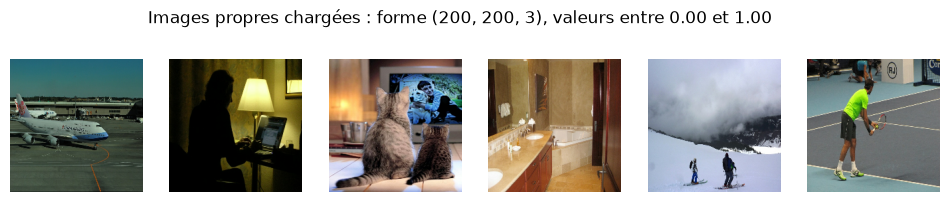

In [5]:
def charger_image(chemin):
    """Protocole « 200 x 200 » : lit un fichier, le convertit en RGB (3 canaux), le redimensionne en IMG x IMG
    (bilinéaire, comme le livrable 1) et ramène les pixels de [0, 255] à [0, 1]."""
    contenu = tf.io.read_file(chemin)
    img = tf.io.decode_image(contenu, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])                 # nécessaire : decode_image ne connaît pas la forme à l'avance
    img = tf.image.resize(img, (IMG, IMG))         # interpolation bilinéaire (par défaut)
    return tf.cast(img, tf.float32) / 255.0

def images_propres(fichiers, melanger=False):
    """Dataset tf.data d'images propres (IMG, IMG, 3) en float32 dans [0, 1] (protocole « 200 x 200 »)."""
    ds = tf.data.Dataset.from_tensor_slices([str(p) for p in fichiers])
    if melanger:
        ds = ds.shuffle(len(fichiers), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(charger_image, num_parallel_calls=AUTOTUNE)

# Aperçu : 6 images propres du jeu d'entraînement, pour vérifier le chargement
plt.figure(figsize=(12, 2.4))
for i, img in enumerate(images_propres(fichiers_train).take(6)):
    plt.subplot(1, 6, i + 1)
    plt.imshow(img.numpy())
    plt.axis("off")
plt.suptitle(f"Images propres chargées : forme {img.shape}, valeurs entre {img.numpy().min():.2f} et {img.numpy().max():.2f}")
plt.show()

## 2. Le bruit et les exemples d'entraînement

### Modèles de bruit

Pour une image propre $x$ (pixels dans $[0,1]$), on fabrique une image bruitée $y$ avec l'un de trois bruits :

| Bruit | Formule | Ce qu'il imite |
|---|---|---|
| **Gaussien additif** | $y = \operatorname{clip}(x + n)$, $n_{i,j,c} \sim \mathcal{N}(0,\sigma^2)$ | le grain du capteur ; $\sigma$ mesure son intensité |
| **Multiplicatif (speckle)** | $y = \operatorname{clip}(x + x \cdot n)$ | un bruit plus fort sur les zones claires |
| **Poivre et sel** | une proportion $p$ des pixels devient noire ou blanche, plus un léger grain | pixels morts, poussières sur la vitre du scanner |

Le `clip` ramène le résultat dans $[0,1]$. Le débruitage est le problème inverse : retrouver $x$ à partir de $y$.

### Choix de conception

* **Débruitage aveugle à bruit mixte.** Pour chaque exemple, on tire le type de bruit (gaussien une fois sur deux, sinon multiplicatif ou poivre et sel) puis son intensité ($\sigma$ entre 0 et 0,30, proportion de pixels touchés entre 1 et 10 %). Le réseau apprend à débruiter **sans connaître le bruit à l'avance**, comme en production, et y compris à laisser intactes les images presque propres ($\sigma$ proche de 0).
* **Patchs en pleine résolution.** Plutôt que des images entières réduites en 200 × 200, on découpe au hasard des carrés de `PATCH` pixels dans les images d'origine, après une réduction aléatoire d'un facteur entre 0,5 et 1. Le réseau voit ainsi le grain à l'échelle où on l'applique (photos en pleine taille sur le site et dans le workflow), et chaque image fournit des centaines d'exemples différents.
* **Bruit et patchs tirés à neuf à chaque passage** : le réseau ne peut apprendre par cœur ni un bruit ni un morceau d'image.
* **Augmentation** : miroir horizontal et rotations d'un quart de tour, qui ne changent pas la nature d'une photo. Pas de modification de couleur : le réseau doit restituer les couleurs d'origine.
* **Bruit fixe pour le test.** Les images de test reçoivent un bruit gaussien **reproductible** ($\sigma = 0{,}15$, graine fixe) : toutes les évaluations comparent les méthodes sur exactement les mêmes images bruitées. Deux protocoles : des **carrés de 256 × 256 au centre des images, en pleine résolution** (pour l'arrêt de l'entraînement, et le plus proche de l'usage réel), et les **images entières réduites en 200 × 200** (le protocole de la version 1, pour comparer).


In [6]:
def bruit_gaussien(x, sigma):
    """Bruit gaussien additif sur un tenseur TensorFlow dans [0, 1] (tirage aléatoire différent à chaque appel)."""
    return tf.clip_by_value(x + tf.random.normal(tf.shape(x), stddev=sigma), 0.0, 1.0)

def bruit_speckle_tf(x, sigma):
    """Bruit multiplicatif : y = x + x.n, plus fort sur les zones claires."""
    return tf.clip_by_value(x + x * tf.random.normal(tf.shape(x), stddev=sigma), 0.0, 1.0)

def bruit_poivre_sel_tf(x, proportion):
    """Une proportion des pixels devient noire ou blanche (les 3 canaux ensemble)."""
    t = tf.random.uniform(tf.shape(x)[:2])[..., None]
    return tf.where(t < proportion / 2, 0.0, tf.where(t < proportion, 1.0, x))

def bruit_mixte(x):
    """Applique à un patch un des trois bruits, tiré au hasard selon PROBA_BRUITS, avec une intensité au hasard."""
    def gaussien():
        return bruit_gaussien(x, tf.random.uniform([], SIGMA_MIN, SIGMA_MAX))
    def speckle():
        return bruit_speckle_tf(x, tf.random.uniform([], 0.05, 0.30))
    def poivre_sel():                               # souvent accompagné d'un léger grain de capteur
        y = bruit_poivre_sel_tf(x, tf.random.uniform([], 0.01, 0.10))
        return bruit_gaussien(y, tf.random.uniform([], 0.0, 0.05))
    p_gauss, p_speckle = PROBA_BRUITS["gaussien"], PROBA_BRUITS["speckle"]
    u = tf.random.uniform([])
    return tf.case([(u < p_gauss, gaussien), (u < p_gauss + p_speckle, speckle)], default=poivre_sel)

def lire_image(chemin):
    """Image entière, à sa taille d'origine, en uint8 RGB."""
    img = tf.io.decode_image(tf.io.read_file(chemin), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return img

def patch_aleatoire(img):
    """Un patch PATCH x PATCH tiré au hasard : réduction d'un facteur entre ECHELLE_MIN et 1 (avec anti-crénelage),
    découpe, miroir et rotation d'un quart de tour. Pixels dans [0, 1]."""
    img = tf.cast(img, tf.float32) / 255.0
    taille = tf.cast(tf.shape(img)[:2], tf.float32)
    echelle = tf.maximum(tf.random.uniform([], ECHELLE_MIN, 1.0), PATCH / tf.reduce_min(taille))  # le patch doit tenir
    img = tf.image.resize(img, tf.cast(tf.round(taille * echelle), tf.int32), antialias=True)
    p = tf.image.random_crop(img, (PATCH, PATCH, 3))
    p = tf.image.random_flip_left_right(p)
    p = tf.image.rot90(p, tf.random.uniform([], 0, 4, dtype=tf.int32))
    return tf.clip_by_value(p, 0.0, 1.0)

# Entraînement : chaque image, décodée une fois puis gardée en mémoire (environ 1 Mo), fournit un patch à chaque
# passage ; patchs, bruits et augmentations sont tirés à neuf à chaque fois (flux infini, PAS_PAR_EPOQUE batchs par époque).
ds_train = (tf.data.Dataset.from_tensor_slices([str(p) for p in fichiers_train]).map(lire_image).cache()
            .repeat().shuffle(len(fichiers_train), seed=SEED)
            .map(patch_aleatoire, num_parallel_calls=AUTOTUNE)
            .map(lambda x: (bruit_mixte(x), x), num_parallel_calls=AUTOTUNE)
            .batch(BATCH).prefetch(AUTOTUNE))

def bruit_gaussien_np(x, sigma, graine=0):
    """Même bruit gaussien, version NumPy reproductible, pour les jeux de test."""
    g = np.random.default_rng(graine)
    return np.clip(x + g.normal(0.0, sigma, x.shape), 0.0, 1.0).astype(np.float32)

def carre_central(chemin, cote=COTE_TEST):
    """Carré cote x cote au centre de l'image, en pleine résolution, pixels dans [0, 1]
    (une image plus petite que le carré est d'abord agrandie)."""
    img = lire_image(str(chemin)).numpy().astype(np.float32) / 255.0
    h, w = img.shape[:2]
    if min(h, w) < cote:
        k = cote / min(h, w)
        img = tf.image.resize(img, (max(cote, round(h * k)), max(cote, round(w * k)))).numpy()
        h, w = img.shape[:2]
    y0, x0 = (h - cote) // 2, (w - cote) // 2
    return img[y0:y0 + cote, x0:x0 + cote]

# Jeux à bruit fixe, en pleine résolution : test (arrêt de l'entraînement, comparaisons) et entraînement (partie 8)
propres_test = np.stack([carre_central(p) for p in fichiers_test])
bruitees_test = bruit_gaussien_np(propres_test, SIGMA_EVAL, graine=7)
propres_train_eval = np.stack([carre_central(p) for p in fichiers_train])
bruitees_train_eval = bruit_gaussien_np(propres_train_eval, SIGMA_EVAL, graine=8)

bruitee, propre = next(iter(ds_train))
print("Un batch d'entraînement : entrée bruitée", bruitee.shape, "| cible propre", propre.shape)
print(f"Test en pleine résolution : {propres_test.shape} | entraînement réévalué : {propres_train_eval.shape}")

Un batch d'entraînement : entrée bruitée (16, 128, 128, 3) | cible propre (16, 128, 128, 3)
Test en pleine résolution : (30, 256, 256, 3) | entraînement réévalué : (118, 256, 256, 3)


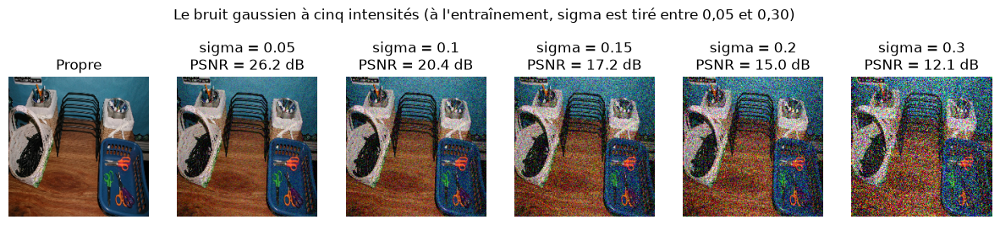

In [7]:
# Visualisation du bruit : une même image à différents niveaux de sigma.
# PSNR (en dB, plus haut = plus proche de l'image propre) : défini en partie 3, calculé ici directement avec TensorFlow.
image_demo = next(iter(images_propres(fichiers_test).take(1)))
niveaux = [0.05, 0.10, 0.15, 0.20, 0.30]
plt.figure(figsize=(15, 3.4))
plt.subplot(1, len(niveaux) + 1, 1)
plt.imshow(image_demo.numpy()); plt.title("Propre"); plt.axis("off")
for k, s in enumerate(niveaux):
    b = bruit_gaussien(image_demo, s)
    plt.subplot(1, len(niveaux) + 1, k + 2)
    plt.imshow(b.numpy())
    plt.title(f"sigma = {s}\nPSNR = {tf.image.psnr(b, image_demo, 1.0).numpy():.1f} dB")
    plt.axis("off")
plt.suptitle("Le bruit gaussien à cinq intensités (à l'entraînement, sigma est tiré entre 0,05 et 0,30)")
plt.show()

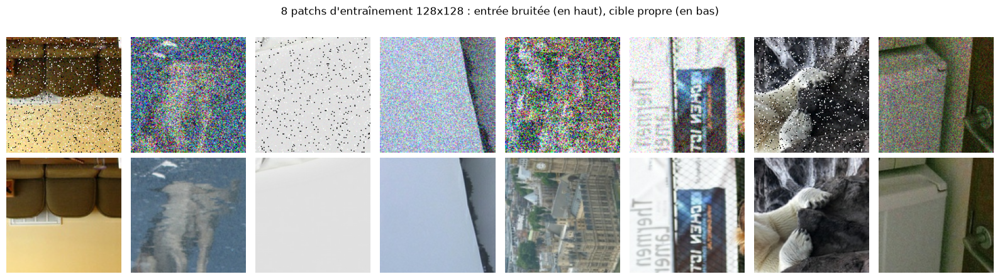

In [8]:
# Exemples tirés par le pipeline d'entraînement : chaque patch a son propre bruit (type et intensité)
n = min(8, bruitee.shape[0])
plt.figure(figsize=(2 * n, 4.6))
for i in range(n):
    plt.subplot(2, n, i + 1); plt.imshow(bruitee[i].numpy()); plt.axis("off")
    plt.subplot(2, n, i + n + 1); plt.imshow(propre[i].numpy()); plt.axis("off")
plt.suptitle(f"{n} patchs d'entraînement {PATCH}x{PATCH} : entrée bruitée (en haut), cible propre (en bas)")
plt.tight_layout(); plt.show()

## 3. Mesurer la qualité, et point de comparaison avec les filtres de convolution

### Trois mesures

| Mesure | Formule | Lecture |
|---|---|---|
| **MSE** (erreur quadratique moyenne) | $\frac{1}{N}\sum (x - \hat x)^2$ | plus bas = mieux ; c'est aussi la **fonction de perte** (partie 5) |
| **PSNR** (rapport signal / bruit de crête) | $10\log_{10}\!\big(1/\text{MSE}\big)$ dB | plus haut = mieux ; **+1 dB** est un gain net, **+3 dB** divise l'erreur par deux ; échelle logarithmique plus lisible que la MSE |
| **SSIM** (similarité structurelle) | compare luminance, contraste et structure localement | entre 0 et 1, plus haut = mieux ; sensible à la **préservation des contours et textures**, ce que la MSE voit mal |

Le PSNR seul peut récompenser une image floue (flou = peu d'erreur moyenne). Le SSIM complète en pénalisant la perte de détails ; on suit donc les deux.

In [9]:
# Mesures sous forme de fonctions Keras : elles seront affichées à chaque époque, pour l'entraînement et le test
def psnr(y_true, y_pred):
    return tf.image.psnr(y_true, y_pred, max_val=1.0)   # un PSNR par image, Keras fait la moyenne

def ssim(y_true, y_pred):
    return tf.image.ssim(y_true, y_pred, max_val=1.0)

def mesurer(propres, estimees):
    """PSNR et SSIM moyens entre deux tableaux NumPy d'images (N, H, W, 3) dans [0, 1]."""
    p = tf.image.psnr(propres, estimees, max_val=1.0).numpy()
    s = tf.image.ssim(propres, estimees, max_val=1.0).numpy()
    return float(p.mean()), float(s.mean())

# Protocole « 200 x 200 » : images de test entières réduites (N_EVAL x 200 x 200 x 3 float32 = environ 30 Mo au plus)
propres_eval = np.stack([x.numpy() for x in images_propres(fichiers_test).take(N_EVAL)])
bruitees_eval = bruit_gaussien_np(propres_eval, SIGMA_EVAL, graine=7)
print("Images d'évaluation 200 x 200 :", propres_eval.shape)
for nom, (pr, br) in {"200 x 200": (propres_eval, bruitees_eval), "pleine résolution": (propres_test, bruitees_test)}.items():
    p, s = mesurer(pr, br)
    print(f"Images bruitées (sigma = {SIGMA_EVAL}), sans aucun traitement, {nom} : PSNR = {p:.2f} dB, SSIM = {s:.3f}")

Images d'évaluation 200 x 200 : (30, 200, 200, 3)
Images bruitées (sigma = 0.15), sans aucun traitement, 200 x 200 : PSNR = 17.17 dB, SSIM = 0.303
Images bruitées (sigma = 0.15), sans aucun traitement, pleine résolution : PSNR = 17.16 dB, SSIM = 0.254


### Référence : les filtres de convolution classiques

Avant de recourir à un réseau de neurones, voyons ce que donnent des **filtres de convolution** simples. Un filtre remplace chaque pixel par une combinaison de ses voisins définie par un petit noyau $K$ :

$$(I * K)(x,y) = \sum_{i}\sum_{j} I(x+i,\,y+j)\;K(i,j)$$

* **Filtre gaussien** : noyau en cloche, chaque pixel devient une moyenne pondérée de son voisinage. Le bruit, indépendant d'un pixel à l'autre, se moyenne et diminue ; mais **les contours et les détails fins sont moyennés eux aussi** : l'image devient floue. Plus le noyau est large (sigma du filtre grand), plus on gagne en débruitage et plus on perd en netteté : c'est un **compromis** que le filtre ne sait pas dépasser, car il traite de la même manière une zone de bruit et un contour.
* **Filtre médian** : chaque pixel prend la valeur médiane de son voisinage. Ce n'est pas une convolution linéaire, mais il préserve mieux les contours et est très efficace contre le bruit « poivre et sel ».

Un auto-encodeur convolutif applique aussi des convolutions, mais **les noyaux sont appris** (au lieu d'être fixés à la main), **empilés** avec des non-linéarités (ReLU) et **à plusieurs échelles** grâce aux pooling : il peut décider, selon le contexte local, de lisser (zone uniforme) ou de préserver (contour).

Pour que la comparaison soit **exigeante**, chaque filtre classique reçoit ci-dessous son **meilleur réglage** (choisi en comparant à l'image propre, ce que l'on ne peut pas faire en production) : c'est un point de comparaison favorable aux filtres.

In [10]:
def filtre_gaussien(lot, s):
    """Convolution de chaque image du lot avec un noyau gaussien d'écart-type s pixels (pas de mélange entre canaux)."""
    return ndimage.gaussian_filter(lot, sigma=(0, s, s, 0)).astype(np.float32)

def filtre_median(lot, k):
    """Filtre médian de fenêtre k x k pixels, canal par canal."""
    return ndimage.median_filter(lot, size=(1, k, k, 1)).astype(np.float32)

REGLAGES_GAUSSIEN = [0.7, 1.0, 1.5, 2.0]   # écart-type du noyau, en pixels
REGLAGES_MEDIAN = [3, 5]                   # taille de la fenêtre

def meilleurs_filtres_classiques(bruitees, propres):
    """Essaie quelques réglages de chaque filtre et garde, pour chacun, celui qui maximise le PSNR moyen
    (réglage 'oracle' : il utilise l'image propre, impossible en production, donc favorable au filtre)."""
    resultats = {}
    for nom, fonction, reglages in [("Gaussien", filtre_gaussien, REGLAGES_GAUSSIEN), ("Médian", filtre_median, REGLAGES_MEDIAN)]:
        meilleur = None
        for r in reglages:
            sortie = fonction(bruitees, r)
            p, s = mesurer(propres, sortie)
            if meilleur is None or p > meilleur["psnr"]:
                meilleur = {"reglage": r, "psnr": p, "ssim": s, "images": sortie}
        resultats[nom] = meilleur
    return resultats

classiques = meilleurs_filtres_classiques(bruitees_eval, propres_eval)
tableau = pd.DataFrame(
    [{"Méthode": "Image bruitée (aucun traitement)", "Réglage": "-", "PSNR (dB)": mesurer(propres_eval, bruitees_eval)[0], "SSIM": mesurer(propres_eval, bruitees_eval)[1]}] +
    [{"Méthode": f"Filtre {nom.lower()}", "Réglage": r["reglage"], "PSNR (dB)": r["psnr"], "SSIM": r["ssim"]} for nom, r in classiques.items()]
).round(3)
print(f"Filtres classiques, bruit gaussien sigma = {SIGMA_EVAL}, {len(propres_eval)} images de test :")
tableau

Filtres classiques, bruit gaussien sigma = 0.15, 30 images de test :


,Méthode,Réglage,PSNR (dB),SSIM
0,Image bruitée (aucun traitement),-,17.172,0.303
1,Filtre gaussien,1.0,23.308,0.585
2,Filtre médian,5,22.389,0.520


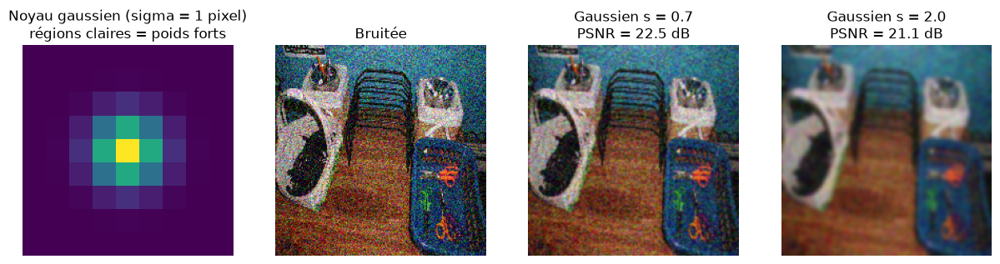

In [11]:
# Un noyau gaussien est une petite image : on le visualise, puis on regarde le compromis flou / bruit résiduel
from scipy.ndimage import gaussian_filter
impulsion = np.zeros((9, 9)); impulsion[4, 4] = 1.0
noyau = gaussian_filter(impulsion, sigma=1.0)            # réponse à une impulsion = le noyau lui-même

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ax[0].imshow(noyau, cmap="viridis"); ax[0].set_title("Noyau gaussien (sigma = 1 pixel)\nrégions claires = poids forts"); ax[0].axis("off")
ax[1].imshow(bruitees_eval[0]); ax[1].set_title("Bruitée"); ax[1].axis("off")
for a, s in zip(ax[2:], [0.7, 2.0]):
    sortie = filtre_gaussien(bruitees_eval[:1], s)[0]
    a.imshow(sortie); a.axis("off")
    a.set_title(f"Gaussien s = {s}\nPSNR = {tf.image.psnr(sortie, propres_eval[0], 1.0).numpy():.1f} dB")
plt.show()

## 4. L'auto-encodeur convolutif : code TensorFlow et architecture

### Principe

Un **auto-encodeur** est composé de deux parties :
* un **encodeur** qui compresse l'image en une représentation compacte : des convolutions extraient des caractéristiques, des `MaxPooling` divisent la résolution par 2 ;
* un **décodeur** qui reconstruit une image de taille d'origine : des `UpSampling2D` multiplient la résolution par 2, des convolutions affinent.

On entraîne le réseau à **retrouver l'image propre à partir de l'image bruitée**. Pour reconstruire, il doit garder ce qui est structuré dans l'image (contours, textures, objets) et laisser tomber ce qui ne l'est pas (le bruit, imprévisible d'un pixel à l'autre) : c'est ce qui le fait débruiter.

### Architecture retenue : un U-Net résiduel

| Élément | Choix | Pourquoi |
|---|---|---|
| Encodeur | 3 niveaux de **2 convolutions 3×3**, filtres **32 → 64 → 128**, `MaxPooling` entre chaque | petits filtres empilés (comme VGG et le livrable 1) ; plus la résolution baisse, plus les motifs sont abstraits |
| Fond du U | 2 convolutions à **256 filtres**, à 1/8 de la résolution | la version 1 serrait l'information dans un goulot de 64 filtres, ce qui écrasait les détails (biais) |
| Décodeur | `UpSampling2D` puis 2 convolutions à chaque niveau | `UpSampling` + convolution plutôt que `Conv2DTranspose`, qui crée des motifs en damier sur les zones lisses |
| **Connexions de saut** (idée du U-Net) | à chaque niveau, le décodeur reçoit aussi les caractéristiques de l'encodeur (`Concatenate`) | les détails de haute résolution passent directement, sans traverser le fond du U |
| **Apprentissage résiduel** (idée de DnCNN) | sortie = entrée + correction, écrêtée dans [0, 1] | le réseau n'apprend que la correction (en gros, le bruit à retirer), plus facile que l'image entière |
| Aucune couche `Flatten` ni `Dense` | réseau **entièrement convolutif** | peu de paramètres pour une image, et **toutes les tailles d'image** acceptées (multiples de 8) : on entraîne sur des patchs, on applique sur des photos entières |
| Normalisation | aucune (pas de Batch Normalization) | essayée : avec le bruit mixte, les moyennes et variances mémorisées pendant l'entraînement ne correspondent pas aux images de test, et le PSNR de test devenait instable d'une époque à l'autre (jusqu'à passer sous celui de l'image bruitée). Les réseaux récents de restauration d'image (EDSR par exemple) s'en passent pour la même raison |


In [12]:
def bloc_conv(x, filtres, n=2):
    """n convolutions 3x3 'same' + ReLU : extraient des motifs à une résolution donnée."""
    for _ in range(n):
        x = layers.Conv2D(filtres, (3, 3), padding="same", activation="relu")(x)
    return x

def construire_debruiteur(filtres=(32, 64, 128), fond=256, nom=NOM_MODELE):
    """U-Net résiduel de débruitage. Entrée de taille libre (None, None, 3) : hauteur et largeur multiples de 8."""
    entree = keras.Input(shape=(None, None, 3), name="image_bruitee")
    x, sauts = entree, []
    for f in filtres:                                         # encodeur : la résolution est divisée par 2 à chaque niveau
        x = bloc_conv(x, f)
        sauts.append(x)                                       # gardé pour le décodeur (connexion de saut)
        x = layers.MaxPooling2D()(x)
    x = bloc_conv(x, fond)                                    # fond du U, à 1/8 de la résolution
    for f, saut in zip(reversed(filtres), reversed(sauts)):   # décodeur : la résolution est multipliée par 2
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, saut])
        x = bloc_conv(x, f)
    correction = layers.Conv2D(3, (3, 3), padding="same", name="correction")(x)   # ce que le réseau retire / ajoute
    somme = layers.Add(name="entree_plus_correction")([entree, correction])        # apprentissage résiduel
    sortie = layers.ReLU(max_value=1.0, name="ecretage_0_1")(somme)                 # pixels gardés dans [0, 1]
    return keras.Model(entree, sortie, name=nom)

modele = construire_debruiteur()
modele.summary()

Model: "cae_saut_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_bruitee       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │        896 │ image_bruitee[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,248 │ conv2d[0][0]      │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, None,      │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │     18,496 │ max_pooling2d[0]… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │     36,928 │ conv2d_2[0][0]    │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, None,      │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │     73,856 │ max_pooling2d_1[… │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, None,      │    147,584 │ conv2d_4[0][0]    │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, None,      │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, None,      │    295,168 │ max_pooling2d_2[… │
│                     │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, None,      │    590,080 │ conv2d_6[0][0]    │
│                     │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, None,      │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None,      │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ None, 384)        │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, None,      │    442,496 │ concatenate[0][0] │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, None,      │    147,584 │ conv2d_8[0][0]    │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, None,      │          0 │ conv2d_9[0][0]  

 Total params: 1,947,715 (7.43 MB)

 Trainable params: 1,947,715 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Paramètres du réseau, couche par couche (tableau généré automatiquement à partir du modèle)
def tableau_parametres(modele):
    lignes = []
    for couche in modele.layers:
        if isinstance(couche, layers.InputLayer):
            continue
        forme = couche.output.shape if hasattr(couche, "output") else None
        lignes.append({"Couche": couche.name, "Type": couche.__class__.__name__,
                       "Sortie (H, L, canaux)": str(tuple(forme[1:])).replace("None", "H/L") if forme is not None else "",
                       "Paramètres": couche.count_params()})
    return pd.DataFrame(lignes)

t = tableau_parametres(modele)
part_conv = t[t["Type"] == "Conv2D"]["Paramètres"].sum() / modele.count_params()
print(f"{modele.name} : {modele.count_params():,} paramètres, {part_conv:.0%} dans les convolutions, aucune couche dense".replace(",", " "))
t

cae_saut_v2 : 1 947 715 paramètres  100% dans les convolutions  aucune couche dense


,Couche,Type,"Sortie (H, L, canaux)",Paramètres
0,conv2d,Conv2D,"(H/L, H/L, 32)",896
1,conv2d_1,Conv2D,"(H/L, H/L, 32)",9248
2,max_pooling2d,MaxPooling2D,"(H/L, H/L, 32)",0
3,conv2d_2,Conv2D,"(H/L, H/L, 64)",18496
4,conv2d_3,Conv2D,"(H/L, H/L, 64)",36928
5,max_pooling2d_1,MaxPooling2D,"(H/L, H/L, 64)",0
6,conv2d_4,Conv2D,"(H/L, H/L, 128)",73856
7,conv2d_5,Conv2D,"(H/L, H/L, 128)",147584
8,max_pooling2d_2,MaxPooling2D,"(H/L, H/L, 128)",0
9,conv2d_6,Conv2D,"(H/L, H/L, 256)",295168


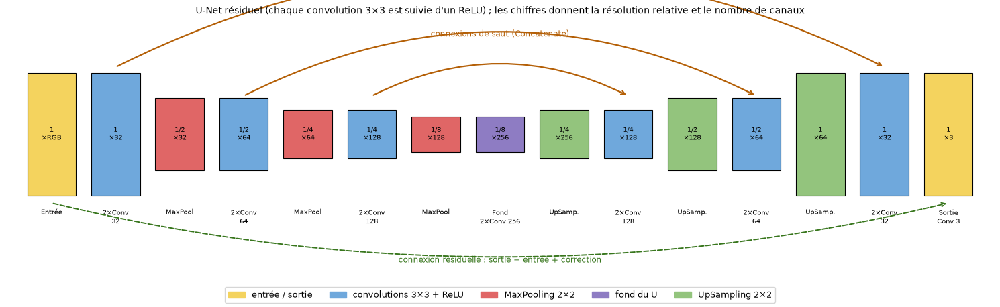

In [14]:
# Schéma de l'architecture, dessiné avec Matplotlib (hauteur du bloc = résolution spatiale, couleur = type de couche)
COULEURS = {"io": "#f4d35e", "conv": "#6fa8dc", "pool": "#e06666", "bott": "#8e7cc3", "up": "#93c47d"}
BLOCS = [("Entrée", 1, "RGB", "io"), ("2×Conv\n32", 1, 32, "conv"), ("MaxPool", 2, 32, "pool"),
         ("2×Conv\n64", 2, 64, "conv"), ("MaxPool", 4, 64, "pool"), ("2×Conv\n128", 4, 128, "conv"),
         ("MaxPool", 8, 128, "pool"), ("Fond\n2×Conv 256", 8, 256, "bott"), ("UpSamp.", 4, 256, "up"),
         ("2×Conv\n128", 4, 128, "conv"), ("UpSamp.", 2, 128, "up"), ("2×Conv\n64", 2, 64, "conv"),
         ("UpSamp.", 1, 64, "up"), ("2×Conv\n32", 1, 32, "conv"), ("Sortie\nConv 3", 1, 3, "io")]

fig, ax = plt.subplots(figsize=(15, 4.6))
for i, (nom, div, canaux, type_) in enumerate(BLOCS):
    h = 0.6 + 2.6 / div
    ax.add_patch(plt.Rectangle((i - 0.38, -h / 2), 0.76, h, color=COULEURS[type_], ec="black", lw=0.8))
    ax.text(i, -1.95, nom, ha="center", va="top", fontsize=7.5)
    ax.text(i, 0, f"{'1' if div == 1 else '1/' + str(div)}\n×{canaux}", ha="center", va="center", fontsize=7)
for (a, b) in [(1, 13), (3, 11), (5, 9)]:   # connexions de saut (même résolution)
    ax.annotate("", xy=(b, 1.75 if a == 1 else 1.0), xytext=(a, 1.75 if a == 1 else 1.0),
                arrowprops=dict(arrowstyle="->", color="#b45f06", lw=1.6, connectionstyle="arc3,rad=-0.25"))
ax.annotate("", xy=(14, -1.8), xytext=(0, -1.8), annotation_clip=False,
            arrowprops=dict(arrowstyle="->", color="#38761d", lw=1.4, ls="--", connectionstyle="arc3,rad=0.12"))
ax.text(7, 2.55, "connexions de saut (Concatenate)", ha="center", color="#b45f06", fontsize=8.5)
ax.text(7, -3.35, "connexion résiduelle : sortie = entrée + correction", ha="center", color="#38761d", fontsize=8.5)
ax.set_xlim(-0.7, len(BLOCS) - 0.3); ax.set_ylim(-3.7, 3.0); ax.axis("off")
ax.set_title("U-Net résiduel (chaque convolution 3×3 est suivie d'un ReLU) ; "
             "les chiffres donnent la résolution relative et le nombre de canaux", fontsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS.values()]
fig.legend(handles, ["entrée / sortie", "convolutions 3×3 + ReLU", "MaxPooling 2×2", "fond du U", "UpSampling 2×2"],
           loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

## 5. La fonction de perte : erreur quadratique moyenne (MSE)

Contrairement au classifieur du livrable 1 (entropie croisée, car la sortie était une probabilité de classe), ici la sortie est une **image** : chaque pixel est une valeur réelle à retrouver. C'est un problème de **régression**, et on minimise l'**erreur quadratique moyenne** entre l'image débruitée $\hat x$ et l'image propre $x$ :

$$\mathcal{L} = \frac{1}{N}\sum_{i=1}^{N}\big(x_i - \hat x_i\big)^2$$

où la somme parcourt tous les pixels et canaux du batch.

* **Justification statistique** : avec un bruit gaussien, minimiser la MSE revient à maximiser la vraisemblance. C'est exactement le critère adapté à notre bruit.
* **Lien direct avec le PSNR** : $\text{PSNR} = 10\log_{10}(1/\mathcal{L})$. Baisser la perte, c'est monter le PSNR.
* **Limite connue** : la MSE traite tous les pixels pareil et pénalise peu le flou (une image légèrement lisse a une MSE faible). Le réseau tend donc à produire des images un peu **trop lisses** : c'est pourquoi on suit aussi le **SSIM** et on regarde les images (voir pistes d'amélioration, partie 11 : perte L1, perte SSIM).
* C'est cette perte que les courbes appellent **« erreur »** (loss) d'entraînement et de test.

## 6. L'algorithme d'optimisation : Adam

Comme dans le livrable 1, on utilise **Adam** (*Adaptive Moment Estimation*) : à chaque batch, TensorFlow calcule le gradient $g_t = \nabla_\theta \mathcal{L}$ par rétropropagation, puis met les poids à jour avec

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)g_t^2 \qquad \theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}$$

($\hat m_t$ et $\hat v_t$ sont $m_t$ et $v_t$ corrigés du biais initial). $m_t$ est un **momentum** (moyenne du gradient) et $v_t$ donne à chaque poids **son propre pas**. Hyperparamètres : $\eta = 10^{-3}$, $\beta_1 = 0{,}9$, $\beta_2 = 0{,}999$, $\varepsilon = 10^{-7}$ (valeurs par défaut de Keras).

Pourquoi Adam à nouveau : il converge vite sans réglage fin du pas, et c'est le même choix que pour le classifieur, donc un seul optimiseur à maintenir côté TouNum.

### Époques et callbacks

Les patchs étant tirés à l'infini, une **époque** n'est plus « un passage sur toutes les images » mais un nombre fixe de mises à jour des poids (`PAS_PAR_EPOQUE`, 250 par défaut), suivi d'une évaluation sur le jeu de test.

| Callback | Réglage | Rôle |
|---|---|---|
| `ReduceLROnPlateau` | surveille `val_loss`, `factor=0.5`, `patience=4`, `min_lr=1e-5` | quand l'erreur de test stagne 4 époques, le pas est divisé par 2 : grands pas au début pour avancer, petits pas ensuite pour affiner |
| `EarlyStopping` | surveille `val_loss`, `patience=12`, `restore_best_weights=True` | arrête l'entraînement quand l'erreur de test ne s'améliore plus pendant 12 époques et **restaure les meilleurs poids** : c'est la première défense contre le sur-apprentissage |


In [15]:
def compiler(modele, learning_rate=1e-3):
    """Perte MSE, optimiseur Adam, et PSNR / SSIM suivis à chaque époque."""
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="mse", metrics=[psnr, ssim])
    return modele

def callbacks():
    return [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1)]

def entrainer_ou_charger(modele, nom_fichier):
    """Entraîne le modèle puis l'enregistre (.keras + historique .csv) dès la fin de l'entraînement ;
    si RETRAIN est False et que les fichiers existent, recharge simplement le modèle et son historique."""
    chemin, chemin_histo = MODELS_DIR / f"{nom_fichier}.keras", MODELS_DIR / f"{nom_fichier}_historique.csv"
    if chemin.exists() and chemin_histo.exists() and not RETRAIN:
        print(f"Rechargement de {chemin}")
        return compiler(keras.models.load_model(chemin, compile=False)), pd.read_csv(chemin_histo)
    compiler(modele)
    t0 = time.time()
    histo = modele.fit(ds_train, steps_per_epoch=PAS_PAR_EPOQUE, epochs=EPOCHS,
                       validation_data=(bruitees_test, propres_test), validation_batch_size=8,
                       callbacks=callbacks(), verbose=2)
    print(f"Entraînement terminé en {(time.time() - t0) / 60:.1f} min")
    modele.save(chemin)                                     # enregistrement dès la fin de l'entraînement
    pd.DataFrame(histo.history).to_csv(chemin_histo, index=False)
    print(f"Modèle enregistré : {chemin.resolve()} (historique : {chemin_histo.name})")
    return modele, pd.DataFrame(histo.history)

In [16]:
# Entraînement du débruiteur (version 2)
modele, histo = entrainer_ou_charger(modele, NOM_MODELE)

Epoch 1/80


/home/rieck/venvs/tf-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1791901666.478357   46554 assert_op.cc:39] Ignoring Assert operator PSNR/Assert/Assert
W0000 00:00:1791901666.478416   46554 assert_op.cc:39] Ignoring Assert operator PSNR/Assert_1/Assert
W0000 00:00:1791901666.479796   46554 assert_op.cc:39] Ignoring Assert operator SSIM/Assert/Assert
W0000 00:00:1791901666.479871   46554 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_1/Assert
W0000 00:00:1791901666.480134   46554 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_2/Assert
W0000 00:00:1791901666.480258   46554 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_3/Assert
W0000 00:00:1791901686.362200   46550 assert_op.cc:39] Ig

250/250 - 104s - 416ms/step - loss: 0.0046 - psnr: 25.2093 - ssim: 0.6458 - val_loss: 0.0034 - val_psnr: 25.0708 - val_ssim: 0.6240 - learning_rate: 0.0010
Epoch 2/80
250/250 - 10s - 39ms/step - loss: 0.0022 - psnr: 27.7293 - ssim: 0.7572 - val_loss: 0.0031 - val_psnr: 25.5371 - val_ssim: 0.6681 - learning_rate: 0.0010
Epoch 3/80
250/250 - 10s - 38ms/step - loss: 0.0019 - psnr: 28.6278 - ssim: 0.7879 - val_loss: 0.0027 - val_psnr: 26.1131 - val_ssim: 0.7048 - learning_rate: 0.0010
Epoch 4/80
250/250 - 10s - 38ms/step - loss: 0.0017 - psnr: 29.3167 - ssim: 0.8123 - val_loss: 0.0024 - val_psnr: 26.6692 - val_ssim: 0.7302 - learning_rate: 0.0010
Epoch 5/80
250/250 - 10s - 38ms/step - loss: 0.0015 - psnr: 29.6607 - ssim: 0.8249 - val_loss: 0.0023 - val_psnr: 26.7597 - val_ssim: 0.7320 - learning_rate: 0.0010
Epoch 6/80
250/250 - 10s - 38ms/step - loss: 0.0014 - psnr: 30.2601 - ssim: 0.8401 - val_loss: 0.0023 - val_psnr: 26.9044 - val_ssim: 0.7358 - learning_rate: 0.0010
Epoch 7/80
250/250 

## 7. Évolution de l'erreur et du PSNR (entraînement et test)

Les quatre courbes demandées par le sujet : **erreur** (MSE) et **qualité** (PSNR, équivalent de l'« accuracy » pour une régression), sur l'entraînement et sur le test. La ligne verticale marque l'époque dont les poids ont été restaurés par l'`EarlyStopping`.

**À lire avec précaution** : l'erreur d'entraînement est une moyenne sur l'époque (le réseau progresse pendant ce temps), sur des patchs à **bruit mixte** d'intensité aléatoire, alors que le test est en **bruit gaussien fixe** ($\sigma = 0{,}15$). Les deux courbes ne sont donc pas mesurées dans les mêmes conditions : pour juger rigoureusement le biais et la variance, la partie 8 réévalue l'entraînement avec **exactement le protocole du test**.


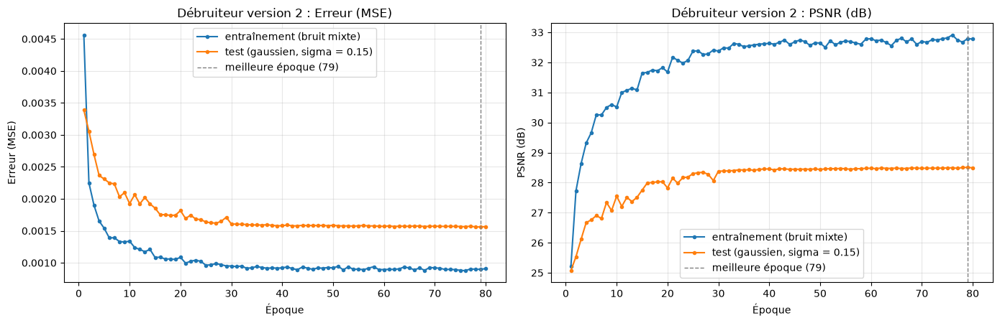

In [17]:
def tracer_courbes(h, nom):
    """Courbes d'erreur (MSE) et de PSNR, entraînement et test."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    ep = np.arange(1, len(h) + 1)
    meilleure = int(np.argmin(h["val_loss"])) + 1
    for ax, cle, titre in [(axes[0], "loss", "Erreur (MSE)"), (axes[1], "psnr", "PSNR (dB)")]:
        ax.plot(ep, h[cle], "o-", ms=3, label="entraînement (bruit mixte)")
        ax.plot(ep, h["val_" + cle], "o-", ms=3, label=f"test (gaussien, sigma = {SIGMA_EVAL})")
        ax.axvline(meilleure, color="gray", ls="--", lw=1, label=f"meilleure époque ({meilleure})")
        ax.set_xlabel("Époque"); ax.set_ylabel(titre); ax.set_title(f"{nom} : {titre}"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

tracer_courbes(histo, "Débruiteur version 2")

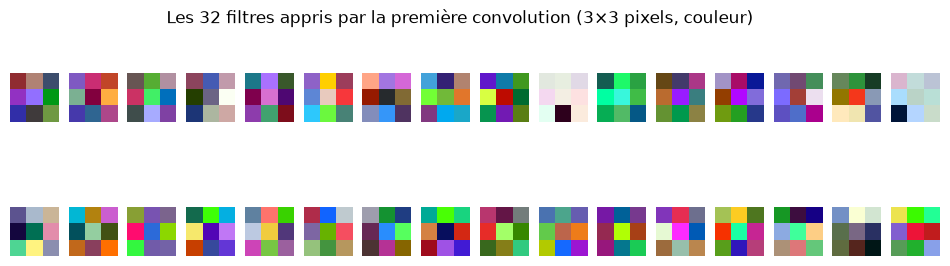

In [18]:
# Qu'ont appris les filtres ? Les 32 noyaux 3x3 de la première convolution, affichés comme de petites images couleur :
# on y retrouve des lisseurs (taches floues, qui moyennent le bruit) et des détecteurs de contours (alternance clair / sombre).
premiere = next(c for c in modele.layers if isinstance(c, layers.Conv2D))
poids = premiere.get_weights()[0]                      # forme (3, 3, 3 canaux, 32 filtres)
plt.figure(figsize=(12, 3.2))
for k in range(poids.shape[-1]):
    f = poids[:, :, :, k]
    f = (f - f.min()) / (f.max() - f.min() + 1e-9)     # mise à l'échelle [0, 1] pour l'affichage
    plt.subplot(2, 16, k + 1); plt.imshow(f, interpolation="nearest"); plt.axis("off")
plt.suptitle("Les 32 filtres appris par la première convolution (3×3 pixels, couleur)")
plt.show()

## 8. Analyse des résultats : compromis biais / variance

Rappel : le **biais** est l'erreur due à un modèle trop simple ou mal entraîné (**sous-apprentissage** : il débruite mal même les images d'entraînement) ; la **variance** est l'erreur due à un modèle qui colle trop aux images d'entraînement (**sur-apprentissage** : bon à l'entraînement, moins bon sur des images nouvelles).
On les lit ainsi : le niveau de l'erreur d'entraînement indique le biais, l'écart entre entraînement et test indique la variance.

### Un protocole rigoureux

Les courbes de la partie 7 comparent un entraînement à bruit mixte et un test à bruit gaussien fixe : l'écart visible mélange donc deux effets. Pour isoler la variance, on **réévalue les images d'entraînement avec exactement le même protocole que le test** (carré central de 256 × 256 en pleine résolution, bruit gaussien $\sigma = 0{,}15$ reproductible). Tout écart restant est alors dû au fait que les images sont déjà connues du réseau ou non.

On fait la même mesure pour la **version 1** (si `cae_saut.keras` existe) : à protocole égal, une erreur d'entraînement plus basse pour la version 2 signifie un biais plus faible.

L'écart relatif est calculé comme $(\text{MSE}_{test} - \text{MSE}_{entr.})/\text{MSE}_{entr.}$. Repère : moins de 10 % = variance faible ; plus de 15 à 20 % = sur-apprentissage notable.


In [19]:
def debruiter_lot(modele, lot, taille_batch=8):
    """Applique un auto-encodeur à un tableau d'images (N, H, W, 3) dans [0, 1]."""
    return modele.predict(lot, batch_size=taille_batch, verbose=0)

def evaluer(modele, bruitees, propres):
    """MSE, PSNR et SSIM moyens d'un modèle sur un lot d'images."""
    sortie = debruiter_lot(modele, bruitees)
    p, s = mesurer(propres, sortie)
    return {"loss": float(np.mean((sortie - propres) ** 2)), "psnr": p, "ssim": s}

chemin_v1 = MODELS_DIR / f"{NOM_VERSION_1}.keras"
modele_v1 = keras.models.load_model(chemin_v1, compile=False) if chemin_v1.exists() else None
print(f"Version 1 : {'chargée depuis ' + str(chemin_v1) if modele_v1 else 'absente, comparaison ignorée'}")
MODELES = {"Version 2 (cae_saut_v2)": modele}
if modele_v1 is not None:
    MODELES["Version 1 (cae_saut)"] = modele_v1

resultats_bv = {nom: (evaluer(m, bruitees_train_eval, propres_train_eval), evaluer(m, bruitees_test, propres_test))
                for nom, m in MODELES.items()}
lignes = []
for nom, (rt, rv) in resultats_bv.items():
    lignes.append({"Modèle": nom, "MSE entr.": rt["loss"], "MSE test": rv["loss"],
                   "Écart relatif MSE": (rv["loss"] - rt["loss"]) / rt["loss"],
                   "PSNR entr. (dB)": rt["psnr"], "PSNR test (dB)": rv["psnr"],
                   "SSIM entr.": rt["ssim"], "SSIM test": rv["ssim"]})
tableau_bv = pd.DataFrame(lignes).set_index("Modèle")
print(f"Protocole identique pour l'entraînement ({len(propres_train_eval)} images) et le test ({len(propres_test)} images) : "
      f"carrés {COTE_TEST} x {COTE_TEST} en pleine résolution, sigma = {SIGMA_EVAL}")
# mise en forme sans DataFrame.style (qui exige jinja2) : arrondis, écart relatif en pourcentage
affichage = tableau_bv.round({"MSE entr.": 5, "MSE test": 5, "PSNR entr. (dB)": 2, "PSNR test (dB)": 2, "SSIM entr.": 3, "SSIM test": 3})
affichage["Écart relatif MSE"] = tableau_bv["Écart relatif MSE"].map("{:+.1%}".format)
affichage

Version 1 : chargée depuis ../models/cae_saut.keras
Protocole identique pour l'entraînement (118 images) et le test (30 images) : carrés 256 x 256 en pleine résolution, sigma = 0.15


,MSE entr.,MSE test,Écart relatif MSE,PSNR entr. (dB),PSNR test (dB),SSIM entr.,SSIM test
Modèle,,,,,,,
Version 2 (cae_saut_v2),0.00180,0.00156,-13.3%,28.12,28.51,0.808,0.793
Version 1 (cae_saut),0.00362,0.00329,-9.0%,24.69,24.98,0.616,0.603


In [20]:
# Diagnostic automatique : les phrases ci-dessous sont calculées à partir des mesures, elles suivent donc les données
for nom, (rt, rv) in resultats_bv.items():
    ecart = (rv["loss"] - rt["loss"]) / rt["loss"]
    if ecart > 0.20:
        verdict = "sur-apprentissage notable : la variance domine, il faut plus de régularisation ou de données"
    elif ecart > 0.10:
        verdict = "variance modérée : léger sur-apprentissage, contenu par l'early stopping"
    else:
        verdict = "variance faible : le réseau généralise bien à des images qu'il n'a jamais vues"
    print(f"{nom} : MSE entraînement {rt['loss']:.5f} -> test {rv['loss']:.5f} (écart {ecart:+.1%}) : {verdict}.")

if modele_v1 is not None:
    (rt2, rv2), (rt1, rv1) = resultats_bv["Version 2 (cae_saut_v2)"], resultats_bv["Version 1 (cae_saut)"]
    baisse = (rt1["loss"] - rt2["loss"]) / rt1["loss"]
    print(f"\nBiais : à l'entraînement, l'erreur de la version 2 est {abs(baisse):.0%} {'plus basse' if baisse > 0 else 'plus haute'} "
          f"que celle de la version 1, soit {rv2['psnr'] - rv1['psnr']:+.2f} dB de PSNR sur le test. ", end="")
    if baisse > 0.1:
        print("La version 1 était limitée par son biais (goulot étroit, entraînement trop court, images réduites) : "
              "la version 2 le réduit.")
    elif baisse < -0.1:
        print("La version 2 a ici plus de biais que la version 1 : son entraînement est sans doute trop court "
              "(augmenter EPOCHS ou PAS_PAR_EPOQUE).")
    else:
        print("Les deux versions ont un biais comparable.")

Version 2 (cae_saut_v2) : MSE entraînement 0.00180 -> test 0.00156 (écart -13.3%) : variance faible : le réseau généralise bien à des images qu'il n'a jamais vues.
Version 1 (cae_saut) : MSE entraînement 0.00362 -> test 0.00329 (écart -9.0%) : variance faible : le réseau généralise bien à des images qu'il n'a jamais vues.

Biais : à l'entraînement, l'erreur de la version 2 est 50% plus basse que celle de la version 1, soit +3.53 dB de PSNR sur le test. La version 1 était limitée par son biais (goulot étroit, entraînement trop court, images réduites) : la version 2 le réduit.


### Comment interpréter ces résultats

1. **Biais.** Le niveau d'erreur d'entraînement dit si le réseau est assez expressif **et assez entraîné**. La version 1 cumulait trois causes de biais : un goulot de 64 filtres qui écrase les détails, moins de 200 mises à jour des poids, et un entraînement sur des images réduites alors qu'on mesure ici en pleine résolution. La comparaison des deux versions à protocole égal mesure ce que les corrections ont apporté.
2. **Variance.** Les auto-encodeurs convolutifs sont **peu sujets au sur-apprentissage** : peu de paramètres comparé au classifieur du livrable 1 (aucune couche dense), un bruit et des patchs neufs à chaque passage qui jouent le rôle d'augmentation de données. L'écart relatif du tableau le quantifie.
3. **Allure des courbes.** L'erreur d'entraînement de la partie 7 peut être plus haute que celle du test : elle est moyennée pendant l'époque et calculée sur du bruit mixte souvent plus fort (jusqu'à $\sigma = 0{,}30$, poivre et sel) que le test ($\sigma = 0{,}15$).
4. **Les callbacks agissent bien comme garde-fous** : `ReduceLROnPlateau` réduit les oscillations en fin d'entraînement, `EarlyStopping` restaure les meilleurs poids.

> **Limite à garder en tête.** Comme dans le livrable 1, le jeu de test sert aussi à choisir l'époque d'arrêt : les scores sont donc **légèrement optimistes**. Pour un score définitif, il faudrait un troisième jeu intact (découpage 70 / 15 / 15) ; l'étude de cas (partie 10) fournit déjà une vérification sur des images jamais vues (les photos du dossier `Test_photos`).


## 9. Évaluation comparative : version 2 contre version 1 et filtres classiques

On compare les « traitements » sur les mêmes images de test bruitées, à plusieurs niveaux de bruit : aucun traitement, filtre gaussien, filtre médian (meilleurs réglages possibles pour chacun), version 1 et version 2 du débruiteur. Deux protocoles :
* **pleine résolution** (carrés de 256 × 256 au centre des 30 images de test), le plus proche de l'usage réel ;
* **200 × 200** (images entières réduites), le protocole de la version 1.

Le niveau **0,40 est volontairement hors de l'intervalle d'entraînement** (0 à 0,30) pour voir comment les modèles **extrapolent** (c'est un test de robustesse, pas de performance nominale).


In [21]:
NIVEAUX = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
ORDRE = ["Aucun traitement", "Filtre gaussien", "Filtre médian"] + list(reversed(MODELES))

def comparer(propres, niveaux):
    """PSNR et SSIM de chaque traitement, pour chaque niveau de bruit (bruit reproductible)."""
    lignes = []
    for sigma in niveaux:
        bruitees = bruit_gaussien_np(propres, sigma, graine=int(sigma * 1000))
        cl = meilleurs_filtres_classiques(bruitees, propres)
        sorties = {"Aucun traitement": bruitees, "Filtre gaussien": cl["Gaussien"]["images"], "Filtre médian": cl["Médian"]["images"]}
        sorties.update({nom: debruiter_lot(m, bruitees) for nom, m in MODELES.items()})
        for nom, img in sorties.items():
            p, s = mesurer(propres, img)
            lignes.append({"sigma": sigma, "Méthode": nom, "PSNR (dB)": p, "SSIM": s})
    return pd.DataFrame(lignes)

resultats = comparer(propres_test, NIVEAUX)            # pleine résolution
resultats_200 = comparer(propres_eval, NIVEAUX)        # protocole 200 x 200 de la version 1
for titre, r in [("PLEINE RÉSOLUTION (carrés 256 x 256)", resultats), ("200 x 200 (protocole de la version 1)", resultats_200)]:
    print(f"\n{titre} - PSNR moyen (dB) :")
    display(r.pivot(index="Méthode", columns="sigma", values="PSNR (dB)").loc[ORDRE].round(2))
    print("SSIM moyen :")
    display(r.pivot(index="Méthode", columns="sigma", values="SSIM").loc[ORDRE].round(3))


PLEINE RÉSOLUTION (carrés 256 x 256) - PSNR moyen (dB) :


sigma,0.05,0.10,0.15,0.20,0.30,0.40
Méthode,,,,,,
Aucun traitement,26.20,20.41,17.15,14.94,12.07,10.31
Filtre gaussien,28.30,25.51,23.99,22.88,20.91,19.26
Filtre médian,26.80,24.42,23.25,22.21,20.34,18.74
Version 1 (cae_saut),28.35,26.69,24.99,23.38,20.64,18.54
Version 2 (cae_saut_v2),32.91,30.21,28.50,27.23,25.34,23.73


SSIM moyen :


sigma,0.05,0.10,0.15,0.20,0.30,0.40
Méthode,,,,,,
Aucun traitement,0.611,0.369,0.254,0.187,0.117,0.081
Filtre gaussien,0.785,0.611,0.563,0.556,0.509,0.451
Filtre médian,0.711,0.546,0.511,0.436,0.326,0.252
Version 1 (cae_saut),0.817,0.710,0.603,0.509,0.370,0.282
Version 2 (cae_saut_v2),0.902,0.840,0.793,0.753,0.680,0.610



200 x 200 (protocole de la version 1) - PSNR moyen (dB) :


sigma,0.05,0.10,0.15,0.20,0.30,0.40
Méthode,,,,,,
Aucun traitement,26.22,20.42,17.17,14.95,12.07,10.31
Filtre gaussien,27.30,24.97,23.31,22.03,20.24,18.68
Filtre médian,25.71,23.78,22.38,21.51,19.86,18.40
Version 1 (cae_saut),27.31,25.96,24.48,22.98,20.36,18.32
Version 2 (cae_saut_v2),31.73,29.00,27.32,26.05,24.24,22.73


SSIM moyen :


sigma,0.05,0.10,0.15,0.20,0.30,0.40
Méthode,,,,,,
Aucun traitement,0.654,0.423,0.303,0.228,0.145,0.102
Filtre gaussien,0.797,0.641,0.584,0.506,0.466,0.441
Filtre médian,0.722,0.572,0.519,0.450,0.347,0.277
Version 1 (cae_saut),0.823,0.729,0.633,0.545,0.410,0.321
Version 2 (cae_saut_v2),0.914,0.854,0.804,0.758,0.681,0.609


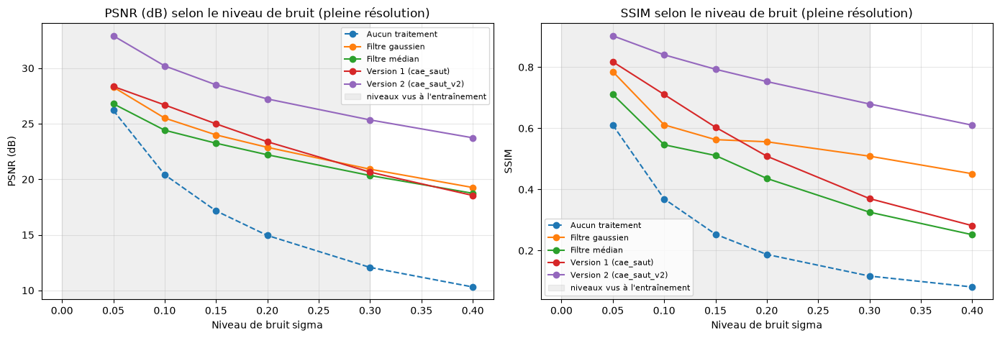

In [22]:
# Courbes qualité en fonction du niveau de bruit, en pleine résolution (zone grisée = niveaux vus à l'entraînement)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, cle in zip(ax, ["PSNR (dB)", "SSIM"]):
    for nom in ORDRE:
        d = resultats[resultats["Méthode"] == nom]
        a.plot(d["sigma"], d[cle], marker="o", label=nom, ls="--" if nom == "Aucun traitement" else "-")
    a.axvspan(SIGMA_MIN, SIGMA_MAX, color="gray", alpha=0.12, label="niveaux vus à l'entraînement")
    a.set_xlabel("Niveau de bruit sigma"); a.set_ylabel(cle); a.grid(alpha=0.3); a.legend(fontsize=8)
    a.set_title(f"{cle} selon le niveau de bruit (pleine résolution)")
plt.tight_layout(); plt.show()

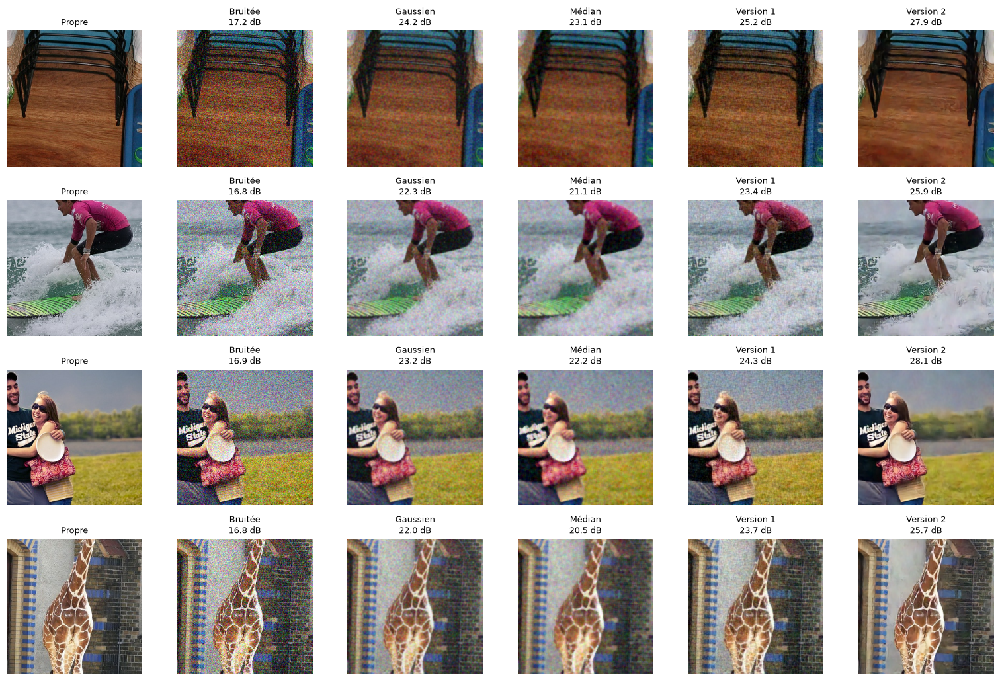

In [23]:
# Comparaison visuelle sur 4 images de test en pleine résolution (sigma = 0,15) ; les chiffres sont le PSNR de chaque image
sigma = SIGMA_EVAL
bruitees = bruit_gaussien_np(propres_test, sigma, graine=int(sigma * 1000))
cl = meilleurs_filtres_classiques(bruitees, propres_test)
colonnes = [("Propre", propres_test), ("Bruitée", bruitees), ("Gaussien", cl["Gaussien"]["images"]), ("Médian", cl["Médian"]["images"])]
colonnes += [(nom.split(" (")[0], debruiter_lot(m, bruitees)) for nom, m in reversed(MODELES.items())]
indices = [0, 1, 2, 3]
fig, axes = plt.subplots(len(indices), len(colonnes), figsize=(2.6 * len(colonnes), 2.6 * len(indices)))
for r, i in enumerate(indices):
    for c, (nom, lot) in enumerate(colonnes):
        axes[r, c].imshow(lot[i]); axes[r, c].axis("off")
        titre = nom
        if nom != "Propre":
            titre += f"\n{tf.image.psnr(lot[i], propres_test[i], 1.0).numpy():.1f} dB"
        axes[r, c].set_title(titre, fontsize=9)
plt.tight_layout(); plt.show()

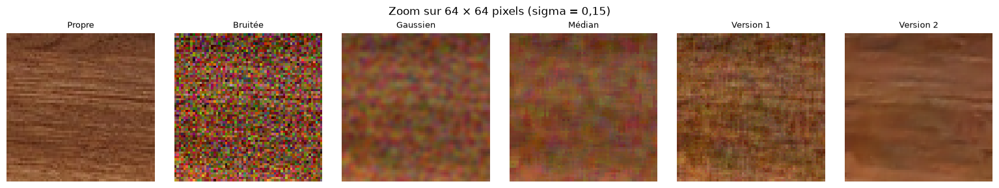

In [24]:
# Zoom sur 64 x 64 pixels : c'est ici qu'on voit la différence entre lisser (flou) et débruiter en gardant les contours
i, y0, x0, t = 0, 96, 96, 64
fig, axes = plt.subplots(1, len(colonnes), figsize=(2.6 * len(colonnes), 2.9))
for a, (nom, lot) in zip(axes, colonnes):
    a.imshow(lot[i][y0:y0 + t, x0:x0 + t], interpolation="nearest"); a.axis("off"); a.set_title(nom, fontsize=9)
plt.suptitle("Zoom sur 64 × 64 pixels (sigma = 0,15)")
plt.tight_layout(); plt.show()

In [25]:
# Synthèse chiffrée automatique au niveau de bruit de référence
for titre, r in [("Pleine résolution", resultats), ("200 x 200", resultats_200)]:
    ref = r[r["sigma"] == SIGMA_EVAL].set_index("Méthode")
    v2 = ref.loc["Version 2 (cae_saut_v2)"]
    meilleur_classique = ref.loc[["Filtre gaussien", "Filtre médian"], "PSNR (dB)"].idxmax()
    texte = (f"{titre}, sigma = {SIGMA_EVAL} : la version 2 obtient {v2['PSNR (dB)']:.2f} dB (SSIM {v2['SSIM']:.3f}), soit "
             f"{v2['PSNR (dB)'] - ref.loc['Aucun traitement', 'PSNR (dB)']:+.2f} dB sur l'image bruitée et "
             f"{v2['PSNR (dB)'] - ref.loc[meilleur_classique, 'PSNR (dB)']:+.2f} dB sur le meilleur filtre classique ({meilleur_classique.lower()})")
    if "Version 1 (cae_saut)" in ref.index:
        v1 = ref.loc["Version 1 (cae_saut)"]
        texte += f" ; {v2['PSNR (dB)'] - v1['PSNR (dB)']:+.2f} dB et {v2['SSIM'] - v1['SSIM']:+.3f} de SSIM sur la version 1"
    print(texte + ".")

Pleine résolution, sigma = 0.15 : la version 2 obtient 28.50 dB (SSIM 0.793), soit +11.35 dB sur l'image bruitée et +4.51 dB sur le meilleur filtre classique (filtre gaussien) ; +3.51 dB et +0.190 de SSIM sur la version 1.
200 x 200, sigma = 0.15 : la version 2 obtient 27.32 dB (SSIM 0.804), soit +10.15 dB sur l'image bruitée et +4.02 dB sur le meilleur filtre classique (filtre gaussien) ; +2.84 dB et +0.171 de SSIM sur la version 1.


### Lecture des résultats

* **Filtres classiques** : un réglage fort débruite mais floute, un réglage faible garde les détails mais laisse du bruit ; le compromis est imposé par le filtre. Leur gain en PSNR est modeste, et leur SSIM chute quand on lisse.
* **Auto-encodeurs** : ils décident localement de lisser ou de préserver, car ce sont des convolutions apprises, non linéaires, vues à plusieurs échelles. La synthèse ci-dessus chiffre l'écart avec les filtres et entre les deux versions ; le zoom montre la différence sur les contours et les textures.
* **Pleine résolution contre 200 × 200** : la version 1, entraînée sur des images réduites, perd surtout en pleine résolution, là où on l'utilise réellement ; la version 2 a été entraînée aux deux échelles.
* **Hors de l'intervalle d'entraînement** (sigma = 0,40) : les performances baissent, car le modèle n'a pas vu ce niveau de bruit. En production il faut couvrir la plage de bruit réellement rencontrée.


## 10. Validation


### (a) Robustesse à d'autres types de bruit

La version 1 n'avait vu que du bruit gaussien ; la version 2 a été entraînée avec un bruit mixte. On les compare (avec les filtres classiques) sur :
* **bruit multiplicatif (speckle)** : $y = x + x\cdot n$, le bruit est plus fort sur les zones claires ;
* **poivre et sel** : 5 % des pixels deviennent noirs ou blancs (pixels morts, poussières) ;
* **flou gaussien** (sigma = 1,5 pixel, plus un léger bruit) : image mal mise au point. Ce n'est **pas** du bruit à enlever mais une perte de détails : on s'attend à ce que le débruiteur n'aide pas.


In [26]:
def bruit_speckle(x, sigma=0.20, graine=1):
    g = np.random.default_rng(graine)
    return np.clip(x + x * g.normal(0, sigma, x.shape), 0, 1).astype(np.float32)

def bruit_poivre_sel(x, proportion=0.05, graine=2):
    g = np.random.default_rng(graine)
    y = x.copy()
    tirage = g.random(x.shape[:3])                       # un tirage par pixel (les 3 canaux changent ensemble)
    y[tirage < proportion / 2] = 0.0                     # pixel noir
    y[(tirage >= proportion / 2) & (tirage < proportion)] = 1.0   # pixel blanc
    return y

def flou_et_bruit(x, s=1.5, sigma=0.03, graine=3):
    return bruit_gaussien_np(filtre_gaussien(x, s), sigma, graine)

types_de_bruit = {"Gaussien (référence, sigma 0,15)": lambda x: bruit_gaussien_np(x, SIGMA_EVAL, 7),
                  "Speckle (multiplicatif)": bruit_speckle,
                  "Poivre et sel (5 %)": bruit_poivre_sel,
                  "Flou + léger bruit": flou_et_bruit}

lignes, exemples = [], {}
for nom, fonction in types_de_bruit.items():
    bruitees = fonction(propres_test)
    cl = meilleurs_filtres_classiques(bruitees, propres_test)
    sorties = {"Aucun traitement": bruitees, "Filtre gaussien": cl["Gaussien"]["images"], "Filtre médian": cl["Médian"]["images"]}
    sorties.update({nom_m: debruiter_lot(m, bruitees) for nom_m, m in reversed(MODELES.items())})
    exemples[nom] = sorties
    for methode, img in sorties.items():
        p, s = mesurer(propres_test, img)
        lignes.append({"Type de bruit": nom, "Méthode": methode, "PSNR (dB)": p, "SSIM": s})
cas_a = pd.DataFrame(lignes)
display(cas_a.pivot(index="Type de bruit", columns="Méthode", values="PSNR (dB)")[ORDRE].round(2))

# Verdict calculé automatiquement : la version 2 améliore-t-elle l'image, et quelle méthode est la meilleure ?
for nom in types_de_bruit:
    d = cas_a[cas_a["Type de bruit"] == nom].set_index("Méthode")["PSNR (dB)"]
    delta = d["Version 2 (cae_saut_v2)"] - d["Aucun traitement"]
    print(f"- {nom} : la version 2 change le PSNR de {delta:+.2f} dB ; meilleure méthode : {d.drop('Aucun traitement').idxmax()}.")

Méthode,Aucun traitement,Filtre gaussien,Filtre médian,Version 1 (cae_saut),Version 2 (cae_saut_v2)
Type de bruit,,,,,
Flou + léger bruit,24.05,24.75,24.75,24.59,25.15
"Gaussien (référence, sigma 0,15)",17.16,23.99,23.23,24.98,28.51
Poivre et sel (5 %),17.88,24.41,28.06,23.07,35.38
Speckle (multiplicatif),21.16,25.80,24.73,26.89,30.91


- Gaussien (référence, sigma 0,15) : la version 2 change le PSNR de +11.35 dB ; meilleure méthode : Version 2 (cae_saut_v2).
- Speckle (multiplicatif) : la version 2 change le PSNR de +9.76 dB ; meilleure méthode : Version 2 (cae_saut_v2).
- Poivre et sel (5 %) : la version 2 change le PSNR de +17.50 dB ; meilleure méthode : Version 2 (cae_saut_v2).
- Flou + léger bruit : la version 2 change le PSNR de +1.10 dB ; meilleure méthode : Version 2 (cae_saut_v2).


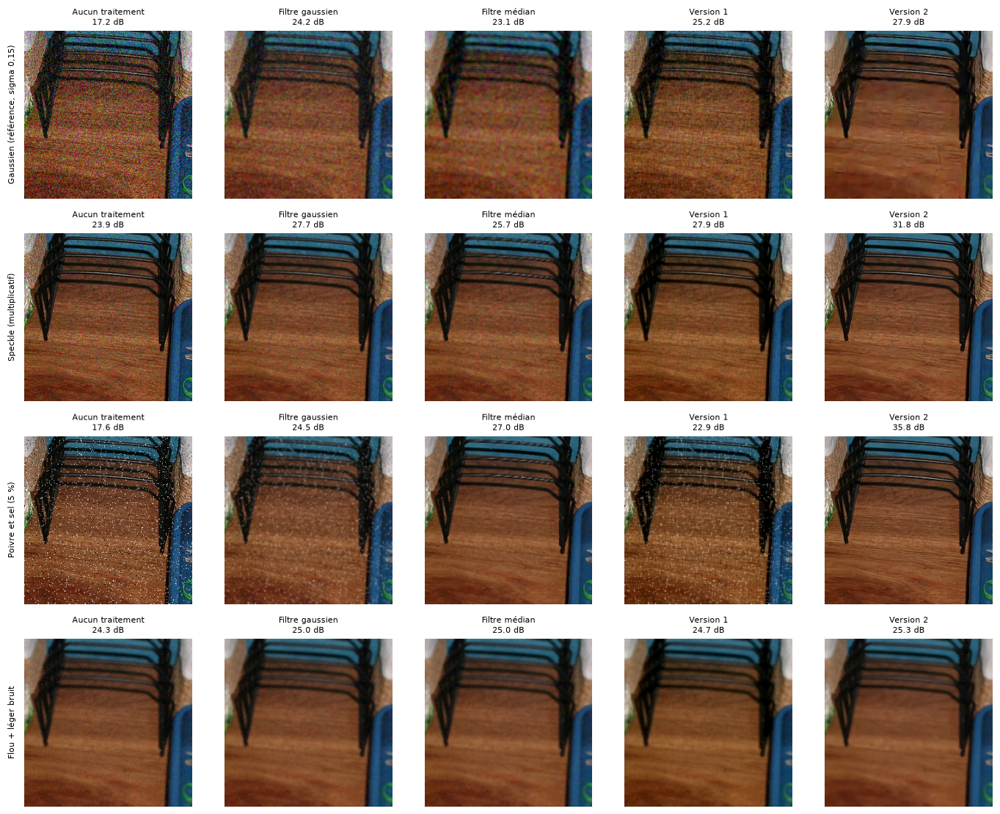

In [27]:
# Les mêmes cas en images (première image de test, pleine résolution)
n_col = len(next(iter(exemples.values())))
fig, axes = plt.subplots(len(types_de_bruit), n_col, figsize=(2.8 * n_col, 2.8 * len(types_de_bruit)))
for r, (nom, sorties) in enumerate(exemples.items()):
    for c, (methode, lot) in enumerate(sorties.items()):
        axes[r, c].imshow(lot[0]); axes[r, c].axis("off")
        axes[r, c].set_title(f"{methode.split(' (')[0]}\n{tf.image.psnr(lot[0], propres_test[0], 1.0).numpy():.1f} dB", fontsize=8)
    axes[r, 0].text(-0.05, 0.5, nom, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

**Ce qu'il faut en retenir.** Un auto-encodeur n'apprend à retirer que les bruits qu'il a vus : c'est pourquoi la version 2 est entraînée avec un bruit mixte, et les tableaux ci-dessus mesurent ce que cela change face au speckle et au poivre et sel. Le flou, lui, n'est pas du bruit : aucun débruiteur ne recrée les détails perdus. Pour aller plus loin, l'idéal reste d'entraîner sur de vrais couples (scan bruité, image propre) fournis par TouNum.


### (b) Impact du bruit sur le classifieur du livrable 1

C'est l'étude de cas qui relie les deux livrables. On donne au classifieur photo / autre du livrable 1 :
1. les photos **propres**,
2. les mêmes photos **bruitées** (sigma = 0,15 puis 0,30),
3. les photos bruitées puis **débruitées** par le modèle B (et, pour comparaison, par le meilleur filtre classique).

**Ce qu'on mesure.** Le dataset de ce livrable contient des photos : la proportion d'images prédites « Photo » est donc le **rappel de la classe Photo**. Si elle chute avec le bruit, le bruit fait rater des photos au tri ; si le débruitage la fait remonter, il **répare** le workflow. (Si le dataset contenait aussi des non-photos, il faudrait mesurer l'accuracy avec les vraies étiquettes.)

Le classifieur doit avoir été sauvegardé par `L1.ipynb` dans `../models/` (`lucky_model2.keras`, 2 classes, ou `lucky_model1.1.keras`, 3 classes). S'il est absent, la cellule le signale et passe : le reste du notebook n'en dépend pas.

In [28]:
def charger_classifieur(dossier=MODELS_DIR, noms=("lucky_model2.keras", "lucky_model1.1.keras")):
    """Recharge le classifieur du livrable 1 s'il existe. Renvoie None sinon (le notebook continue)."""
    for nom in noms:
        chemin = pathlib.Path(dossier) / nom
        if chemin.exists():
            print(f"Classifieur du livrable 1 chargé : {chemin}")
            return keras.models.load_model(chemin, compile=False)
    print(f"Classifieur du livrable 1 introuvable dans {pathlib.Path(dossier).resolve()} : étude (b) ignorée.")
    return None

def proba_photo(classifieur, images):
    """Probabilité de la classe « Photo » pour des images dans [0, 1] de forme (N, H, W, 3).

    Le classifieur du livrable 1 contient déjà sa couche Rescaling(1/255) : il attend des pixels dans [0, 255].
    La classe « Photo » est la DERNIÈRE sortie (ordre alphabétique des dossiers : Others, [Painting,] Photo)."""
    images_255 = tf.image.resize(images * 255.0, (200, 200)).numpy()      # même taille que le livrable 1, bilinéaire
    sortie = classifieur.predict(images_255, batch_size=16, verbose=0)
    if not np.allclose(sortie.sum(axis=1), 1.0, atol=1e-3):                # logits (lucky_model2) : on applique le softmax
        sortie = tf.nn.softmax(sortie).numpy()
    return sortie[:, -1], sortie.argmax(axis=1) == sortie.shape[1] - 1

classifieur = charger_classifieur()
if classifieur is not None:
    lignes = []
    for sigma in [0.0, 0.15, 0.30]:
        bruitees = propres_eval if sigma == 0 else bruit_gaussien_np(propres_eval, sigma, graine=int(sigma * 1000))
        variantes = {"Bruitée" if sigma else "Propre (référence)": bruitees}
        if sigma:
            variantes["Débruitée (version 2)"] = debruiter_lot(modele, bruitees)
            variantes["Débruitée (meilleur filtre classique)"] = max(
                meilleurs_filtres_classiques(bruitees, propres_eval).values(), key=lambda r: r["psnr"])["images"]
        for nom, lot in variantes.items():
            proba, est_photo = proba_photo(classifieur, lot)
            lignes.append({"sigma": sigma, "Images données au classifieur": nom,
                           "Reconnues « Photo » (rappel)": est_photo.mean(), "Probabilité moyenne de Photo": proba.mean()})
    cas_b = pd.DataFrame(lignes)
    affichage = cas_b.round({"Probabilité moyenne de Photo": 3})   # mise en forme sans jinja2
    affichage["Reconnues « Photo » (rappel)"] = cas_b["Reconnues « Photo » (rappel)"].map("{:.1%}".format)
    display(affichage)

Classifieur du livrable 1 chargé : ../models/lucky_model2.keras


,sigma,Images données au classifieur,Reconnues « Photo » (rappel),Probabilité moyenne de Photo
0,0.00,Propre (référence),90.0%,0.852
1,0.15,Bruitée,23.3%,0.233
2,0.15,Débruitée (version 2),93.3%,0.877
3,0.15,Débruitée (meilleur filtre classique),26.7%,0.306
4,0.30,Bruitée,3.3%,0.054
5,0.30,Débruitée (version 2),86.7%,0.809
6,0.30,Débruitée (meilleur filtre classique),3.3%,0.095


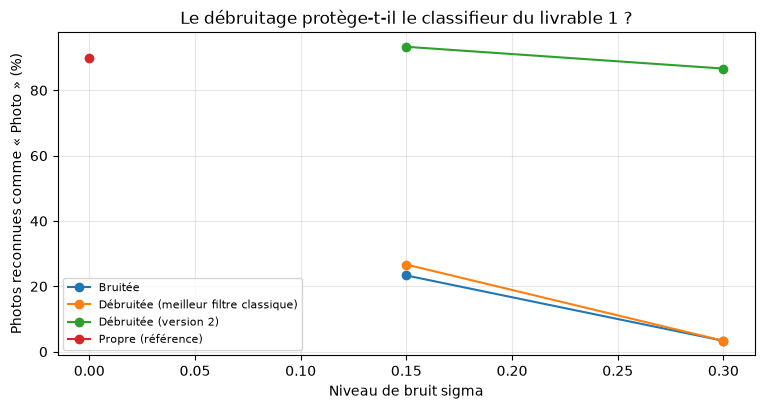

In [29]:
if classifieur is not None:
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for nom, d in cas_b.groupby("Images données au classifieur"):
        ax.plot(d["sigma"], d["Reconnues « Photo » (rappel)"] * 100, "o-", label=nom)
    ax.set_xlabel("Niveau de bruit sigma"); ax.set_ylabel("Photos reconnues comme « Photo » (%)")
    ax.set_title("Le débruitage protège-t-il le classifieur du livrable 1 ?"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.show()

**Lecture.** La ligne « Propre » donne le rappel de référence du classifieur ; l'écart avec « Bruitée » est le coût du bruit pour le workflow ; l'écart entre « Débruitée » et « Bruitée » est ce que gagne l'étape de débruitage. Un classifieur entraîné sur des images propres est en général sensible au bruit, car le grain modifie les textures sur lesquelles il s'appuie (livrable 1 : le grain d'une photo est un indice pour la reconnaître). Remarque à garder pour la soutenance : si le débruitage ne ramène pas complètement le rappel à la référence, c'est que le lissage a lui-même un peu modifié les textures ; une piste est de **ré-entraîner le classifieur sur des images débruitées**.

### (c) Images réelles de taille quelconque : `Test_photos`

Le réseau est entièrement convolutif : on l'applique à des images **dans leur taille d'origine**, sans les redimensionner en 200×200. Seule contrainte : hauteur et largeur multiples de 8 (trois `MaxPooling` successifs). La fonction `debruiter_image` complète l'image par symétrie sur les bords (`reflect`) puis découpe le résultat pour retrouver la taille d'origine.

Ces douze images n'ont jamais été vues pendant l'entraînement, on leur ajoute un bruit gaussien (sigma = 0,15) puis on débruite.

W0000 00:00:1791902596.019010   60114 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.04GiB (6488916874 bytes) by rematerialization; only reduced to 8.14GiB (8745357360 bytes), down from 8.14GiB (8745357360 bytes) originally
W0000 00:00:1791902606.081004   46554 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 8.14GiB (rounded to 8738857728)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
W0000 00:00:1791902606.081367   46554 bfc_allocator.cc:513] *_******_____*______________________________________________________________________________________
W0000 00:00:1791902606.689589   60115 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.03GiB (6475445540 bytes) by rematerialization; only reduced to 24.41GiB (26210070576 bytes), down from 24.41GiB (26210070576 

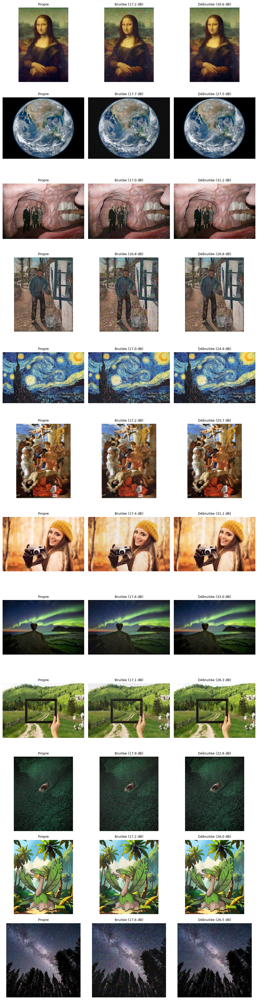

,Image,Taille,PSNR bruitée,PSNR débruitée,Gain (dB)
0,Jauconde.jpg,366×546,17.209999,30.610001,13.40
1,Terre.jpg,946×710,17.709999,27.510000,9.79
2,etrange.jpg,673×456,17.010000,31.230000,14.22
3,homme devant fenetre.jpg,250×315,16.770000,26.639999,9.88
4,nuit sous les étoiles.jpg,565×353,17.030001,24.920000,7.89
5,peinture wiki.jpg,753×1024,17.200001,25.700001,8.50
6,photo1.jpg,678×452,17.389999,31.120001,13.73
7,photo2.jpg,678×452,17.580000,32.950001,15.37
8,photo3.jpg,678×452,17.070000,26.340000,9.27
9,photo4.jpg,494×619,17.920000,22.580000,4.66


Gain moyen sur les 12 images : +10.37 dB (minimum +4.66, maximum +15.37).


In [30]:
def debruiter_image(modele, image, max_cote=None):
    """Débruite UNE image de taille quelconque.

    image : tableau (H, W, 3) en uint8 [0, 255] ou en float [0, 1] ; renvoie un tableau float32 (H, W, 3) dans [0, 1].
    max_cote : si renseigné, l'image est réduite pour que son grand côté ne dépasse pas cette valeur (limite la mémoire).
    Le réseau demande H et W multiples de 8 : on complète par symétrie sur les bords puis on rogne le résultat.
    """
    x = np.asarray(image)
    x = x.astype(np.float32) / 255.0 if x.dtype == np.uint8 else x.astype(np.float32)
    if max_cote and max(x.shape[:2]) > max_cote:
        facteur = max_cote / max(x.shape[:2])
        x = tf.image.resize(x, (int(x.shape[0] * facteur), int(x.shape[1] * facteur)), antialias=True).numpy()
    h, w = x.shape[:2]
    pad_h, pad_w = (-h) % 8, (-w) % 8
    x_pad = np.pad(x, ((0, pad_h), (0, pad_w), (0, 0)), mode="reflect")
    sortie = modele.predict(x_pad[None], verbose=0)[0]
    return np.clip(sortie[:h, :w], 0.0, 1.0)

dossier_test = pathlib.Path("../Test_photos")   # les douze images de test du projet
photos_test = lister_images(dossier_test) if dossier_test.is_dir() else []
if not photos_test:
    print(f"Dossier {dossier_test.resolve()} absent ou vide : étude (c) ignorée.")
else:
    n = len(photos_test)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.2 * n), squeeze=False)
    lignes = []
    for r, chemin in enumerate(photos_test):
        propre = np.asarray(Image.open(chemin).convert("RGB")).astype(np.float32) / 255.0
        bruitee = bruit_gaussien_np(propre, SIGMA_EVAL, graine=r)
        debruitee = debruiter_image(modele, bruitee)
        p0 = tf.image.psnr(bruitee, propre, 1.0).numpy(); p1 = tf.image.psnr(debruitee, propre, 1.0).numpy()
        lignes.append({"Image": chemin.name, "Taille": f"{propre.shape[1]}×{propre.shape[0]}", "PSNR bruitée": p0, "PSNR débruitée": p1, "Gain (dB)": p1 - p0})
        for c, (titre, img) in enumerate([("Propre", propre), (f"Bruitée ({p0:.1f} dB)", bruitee), (f"Débruitée ({p1:.1f} dB)", debruitee)]):
            axes[r, c].imshow(img); axes[r, c].axis("off"); axes[r, c].set_title(titre, fontsize=9)
    plt.tight_layout(); plt.show()
    cas_c = pd.DataFrame(lignes).round(2)
    display(cas_c)
    print(f"Gain moyen sur les {n} images : {cas_c['Gain (dB)'].mean():+.2f} dB (minimum {cas_c['Gain (dB)'].min():+.2f}, maximum {cas_c['Gain (dB)'].max():+.2f}).")

**Ce qu'il faut regarder dans ce test** : le gain est-il positif sur **toutes** les images ? Les images au contenu très différent de l'entraînement (peintures, dessins, images de synthèse présentes dans `Test_photos`) sont les plus délicates : un auto-encodeur entraîné sur des photos peut y mal restituer les aplats ou les traits fins. Ces images ne devraient de toute façon pas arriver jusqu'ici : elles sont filtrées en amont par le classifieur du livrable 1.

## 11. Méthodes pour améliorer le débruitage et le compromis biais / variance

| Méthode | Réduit surtout | Utilisé dans la version 2 ? | Ce qu'on ferait |
|---|---|---|---|
| **Plus de mises à jour des poids** (patchs tirés à l'infini) | le biais | oui (`PAS_PAR_EPOQUE`, `EPOCHS`) | c'est le premier levier : la version 1 n'avait fait que quelques centaines de pas |
| **Patchs en pleine résolution, plusieurs échelles** | l'écart entraînement / usage | oui (`PATCH`, `ECHELLE_MIN`) | patchs plus grands (`PATCH = 192`) pour plus de contexte |
| **Bruit mixte** | l'écart bruit simulé / bruit réel | oui (`PROBA_BRUITS`) | ajouter d'autres bruits réels : compression JPEG, bruit de Poisson, bandes de scanner |
| **Early stopping** | la variance | oui (`patience=12`, meilleurs poids restaurés) | garder ; c'est le garde-fou principal |
| **Réduction du pas** (`ReduceLROnPlateau`) | l'instabilité de fin d'entraînement | oui | on peut tester une décroissance cosinus |
| **Augmentation** (miroir, quarts de tour) | la variance | oui | recadrages et échelles déjà aléatoires ; pas de changement de couleur |
| **Batch Normalization** | biais et variance | essayée, retirée | instable en évaluation avec le bruit mixte (partie 4) ; à retester avec un seul type de bruit ou une normalisation par image |
| **Connexions de saut + apprentissage résiduel** | le biais | oui | c'est ce qui garde les détails fins |
| **Réseau plus large / plus profond** (48-96-192 filtres, 4 niveaux) | le biais | non | `construire_debruiteur(filtres=(48, 96, 192), fond=384)` : plus de capacité, calcul plus long |
| **Régularisation L2** (*weight decay*) | la variance | non | `AdamW` ; utile seulement si l'écart entraînement / test de la partie 8 augmente |
| **Plus de données** | la variance | partiellement | ajouter des photos propres au dossier `dataset/` (par exemple les photos du livrable 1) |
| **Autres fonctions de perte** | la netteté | non | perte **L1** (`mae`, moins lissante que la MSE), `1 - SSIM`, ou une combinaison MSE + SSIM |
| **Vrai bruit de numérisation** | l'écart bruit simulé / bruit réel | non | entraîner sur des couples (scan bruité, version propre) réels de TouNum |

### Limites de l'approche actuelle

* **Bruit simulé** : les scores sont calculés sur du bruit fabriqué, pas sur du bruit réel de scanner.
* **Peu d'images** : 148 images au total ; les patchs multiplient les exemples, mais pas la variété des scènes.
* **La MSE favorise les images un peu lisses** : le PSNR peut monter alors que de fines textures disparaissent ; d'où le suivi du SSIM et le contrôle visuel.
* **Score optimiste** : le jeu de test sert à choisir l'époque d'arrêt (voir partie 8).


## 12. Intégration au workflow : une fonction réutilisable pour le livrable 3

Pour que TouNum puisse **mettre la solution en production** et que le livrable 3 reprenne cette étape telle quelle, la fonction ci-dessous regroupe le workflow *dossier d'images en entrée → dossier d'images propres en sortie* :

1. (optionnel) le classifieur du livrable 1 écarte ce qui n'est pas une photo ;
2. le débruiteur traite chaque photo retenue, **à sa taille d'origine** (limitée à `max_cote` pixels pour borner la mémoire) ;
3. l'image débruitée est enregistrée en **PNG** (sans perte : on ne ré-introduit pas d'artefacts de compression) et un **rapport** (DataFrame) indique ce qui a été fait.

Le réseau de captioning (livrable 3) redimensionnera ensuite ces images à la taille attendue par son CNN pré-entraîné ; cette réduction se fait **après** le débruitage.

Démonstration ci-dessous : on fabrique un dossier d'images bruitées à partir de `Test_photos` (cas réel d'un lot de scans), puis on lance la fonction.

In [31]:
def appliquer_debruitage(dossier_entree, dossier_sortie, modele, classifieur=None, seuil_photo=0.5, max_cote=1024):
    """Étape « prétraitement » du workflow TouNum.

    dossier_entree : dossier d'images (sous-dossiers acceptés) ; dossier_sortie : créé si besoin (PNG).
    classifieur    : modèle du livrable 1 (facultatif) ; les images dont la probabilité de « Photo » < seuil_photo sont écartées.
    Renvoie un DataFrame : une ligne par image (fichier, taille, probabilité de Photo, traitée ou non, fichier de sortie).
    """
    dossier_entree, dossier_sortie = pathlib.Path(dossier_entree), pathlib.Path(dossier_sortie)
    dossier_sortie.mkdir(parents=True, exist_ok=True)
    lignes = []
    for chemin in lister_images(dossier_entree):
        image = np.asarray(Image.open(chemin).convert("RGB"))
        p_photo = np.nan
        if classifieur is not None:
            p_photo = float(proba_photo(classifieur, image[None].astype(np.float32) / 255.0)[0][0])
            if p_photo < seuil_photo:
                lignes.append({"fichier": chemin.name, "taille": f"{image.shape[1]}×{image.shape[0]}", "P(photo)": p_photo,
                               "traitée": False, "sortie": None})
                continue
        propre = debruiter_image(modele, image, max_cote=max_cote)
        sortie = dossier_sortie / (chemin.stem + ".png")
        Image.fromarray((propre * 255.0 + 0.5).astype(np.uint8)).save(sortie)
        lignes.append({"fichier": chemin.name, "taille": f"{propre.shape[1]}×{propre.shape[0]}", "P(photo)": p_photo,
                       "traitée": True, "sortie": str(sortie)})
    rapport = pd.DataFrame(lignes)
    print(f"{int(rapport['traitée'].sum())} image(s) débruitée(s) sur {len(rapport)}, enregistrées dans {dossier_sortie.resolve()}")
    return rapport

# Démonstration sur un lot de scans simulé : Test_photos + bruit gaussien (sigma = 0,15)
if photos_test:
    lot_bruite = pathlib.Path("./sorties/demo_lot_bruite")
    lot_bruite.mkdir(parents=True, exist_ok=True)
    for r, chemin in enumerate(photos_test):
        img = np.asarray(Image.open(chemin).convert("RGB")).astype(np.float32) / 255.0
        Image.fromarray((bruit_gaussien_np(img, SIGMA_EVAL, graine=r) * 255).astype(np.uint8)).save(lot_bruite / (chemin.stem + ".png"))
    t0 = time.time()
    rapport = appliquer_debruitage(lot_bruite, "./sorties/demo_lot_debruite", modele, classifieur=classifieur)
    print(f"Temps total : {time.time() - t0:.1f} s, soit {(time.time() - t0) / len(rapport) * 1000:.0f} ms par image (sur {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'})")
    display(rapport)

0 image(s) débruitée(s) sur 15, enregistrées dans /mnt/d/A5/projet/Livrable2/sorties/demo_lot_debruite
Temps total : 1.1 s, soit 75 ms par image (sur GPU)


,fichier,taille,P(photo),traitée,sortie
0,Jauconde.png,366×546,0.000082,False,None
1,Noise_salt_and_pepper.png,250×334,0.005684,False,None
2,P4120125.png,1500×2000,0.089915,False,None
3,Terre.png,946×710,0.384816,False,None
4,etrange.png,673×456,0.075318,False,None
5,homme devant fenetre.png,250×315,0.152785,False,None
6,images.png,340×344,0.002474,False,None
7,nuit sous les étoiles.png,565×353,0.000423,False,None
8,peinture wiki.png,753×1024,0.012737,False,None
9,photo1.png,678×452,0.002551,False,None


W0000 00:00:1791902827.838865   63778 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.04GiB (6485939492 bytes) by rematerialization; only reduced to 6.16GiB (6611533872 bytes), down from 6.16GiB (6611533872 bytes) originally
W0000 00:00:1791902837.920163   46553 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 6.15GiB (rounded to 6608782080)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
W0000 00:00:1791902837.921471   46553 bfc_allocator.cc:513] **********___*______________________________________________________________________________________
W0000 00:00:1791902837.931834   63777 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.03GiB (6479493450 bytes) by rematerialization; only reduced to 6.17GiB (6622642224 bytes), down from 6.17GiB (6622642224 byte

3 image(s) débruitée(s) sur 3, enregistrées dans /mnt/d/A5/projet/Livrable2/sorties/images_bruitees_debruitees


,fichier,taille,P(photo),traitée,sortie
0,Noise_salt_and_pepper.png,250×334,NaN,True,sorties/images_bruitees_debruitees/Noise_salt_...
1,P4120125.jpg,768×1024,NaN,True,sorties/images_bruitees_debruitees/P4120125.png
2,images.jpg,340×344,NaN,True,sorties/images_bruitees_debruitees/images.png


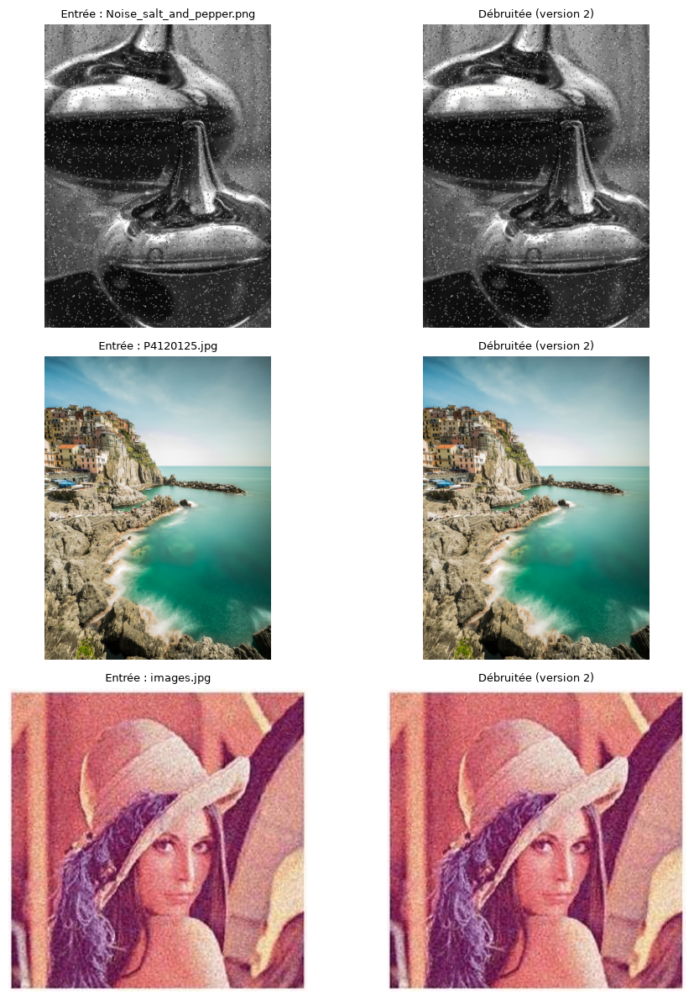

In [32]:
# Test de appliquer_debruitage sur des images réellement bruitées (dossier images_bruitees), sans ajouter de bruit
dossier_entree = pathlib.Path("./images_bruitees")
dossier_sortie = pathlib.Path("./sorties/images_bruitees_debruitees")

rapport_perso = appliquer_debruitage(
    dossier_entree,
    dossier_sortie,
    modele,              # débruiteur version 2
    classifieur=None,    # mettre classifieur=classifieur pour écarter d'abord les non-photos (livrable 1)
    seuil_photo=0.5,
    max_cote=1024,       # grand côté limité à 1024 px pour borner la mémoire
)
display(rapport_perso)

# Comparaison avant / après pour chaque image traitée
traitees = rapport_perso[rapport_perso["traitée"]]
if len(traitees):
    fig, axes = plt.subplots(len(traitees), 2, figsize=(10, 4 * len(traitees)), squeeze=False)
    for r, (_, ligne) in enumerate(traitees.iterrows()):
        avant = Image.open(dossier_entree / ligne["fichier"]).convert("RGB")
        apres = Image.open(ligne["sortie"])
        axes[r, 0].imshow(avant); axes[r, 0].set_title(f"Entrée : {ligne['fichier']}", fontsize=9)
        axes[r, 1].imshow(apres); axes[r, 1].set_title("Débruitée (version 2)", fontsize=9)
        for ax in axes[r]: ax.axis("off")
    plt.tight_layout(); plt.show()


### Publication sur le site de test

Le débruiteur est enregistré dans `models/` dès la fin de son entraînement (partie 7). Le site de test du projet (`Test_website/index.html`) s'en sert dans deux onglets :

* **Débruitage** : une image avant / après, avec le gain de PSNR et de SSIM mesuré comme ici (bruit gaussien ajouté à une image propre) ;
* **Pipeline** : un dossier passe par le classifieur du livrable 1, puis les photos gardées par le débruiteur.

Le site calcule dans le navigateur : il faut d'abord exporter le modèle à son format. La cellule ci-dessous lance `Test_website/convertir_modeles.py`, qui lit la liste des modèles du site (`Test_website/catalogue.json`), exporte ceux qui sont nouveaux ou ré-entraînés et **vérifie qu'ils donnent les mêmes résultats que Keras**. Il suffit ensuite de recharger la page (sous Windows, un double-clic sur `convertir_modeles.bat` fait la même chose).


In [33]:
# Export des modèles enregistrés vers le site de test. Le script tourne dans un processus à part, sur le
# processeur (CUDA_VISIBLE_DEVICES vide) : la carte graphique reste à ce notebook.
import subprocess
import sys

PUBLIER_SUR_LE_SITE = True
if PUBLIER_SUR_LE_SITE:
    script = pathlib.Path("../Test_website/convertir_modeles.py").resolve()
    resultat = subprocess.run([sys.executable, str(script)], capture_output=True, text=True,
                              env={**os.environ, "CUDA_VISIBLE_DEVICES": "", "TF_CPP_MIN_LOG_LEVEL": "3"})
    print(resultat.stdout)
    if resultat.returncode != 0:
        print(resultat.stderr[-3000:])


[L1_classification/model_photo_autre] à jour
[L1_classification/model_photo_autre_peinture] à jour
[L2_debruitage/cae_saut_v2] conversion de cae_saut_v2.keras...
[L2_debruitage/cae_saut_v2] OK : entrée ?x?x3, image -> image (côtés multiples de 8), 1,947,715 paramètres en float32, écart max avec Keras 1.3e-06
[L2_debruitage/cae_saut] à jour

L1_classification : model_photo_autre, model_photo_autre_peinture
L2_debruitage : cae_saut_v2, cae_saut
Recharge la page du site (F5).



## Conclusion

* **Méthode.** Un auto-encodeur convolutif entièrement convolutif (U-Net résiduel), écrit et entraîné de zéro avec TensorFlow / Keras, sans réseau pré-entraîné. Il apprend à retrouver une photo propre à partir d'une photo bruitée, sur des **patchs en pleine résolution** tirés à l'infini, avec un **bruit mixte** (gaussien, multiplicatif, poivre et sel) d'intensité aléatoire. Perte **MSE**, optimiseur **Adam**, `ReduceLROnPlateau` et `EarlyStopping`. Le test est à bruit fixe et reproductible.
* **Version 2 contre version 1.** Les limites de la version 1 (entraînement très court, images réduites, bruit gaussien seul, goulot étroit) étaient surtout des causes de **biais** ; la partie 8 le mesure à protocole égal et la partie 9 chiffre le gain, en pleine résolution comme en 200 × 200. La **variance** reste faible (écart entraînement / test mesuré en partie 8).
* **Comparaison avec la référence** : les filtres de convolution classiques (gaussien, médian), pourtant réglés avec l'image propre, imposent un compromis flou / bruit que les convolutions apprises dépassent ; la partie 9 le vérifie chiffres à l'appui selon le niveau de bruit.
* **Étude de cas.** (a) le bruit mixte rend le débruiteur utile au-delà du bruit gaussien, mais le flou reste hors de portée ; (b) le coût du bruit pour le classifieur du livrable 1 et le gain du débruitage sont mesurés ; (c) le réseau s'applique à des images réelles de toute taille.
* **Pour TouNum.** La fonction `appliquer_debruitage` (partie 12) est l'étape « prétraitement » prête à brancher entre le classifieur (livrable 1) et le captioning (livrable 3). Le modèle est enregistré dans `models/cae_saut_v2.keras` (avec son historique `.csv`), `RETRAIN = False` le recharge sans ré-entraîner, et le site de test l'utilise (onglets « Débruitage » et « Pipeline »).
* **Limites et suite.** Le bruit est simulé : la priorité est de récupérer quelques vrais couples bruité / propre pour valider, puis ré-entraîner ; on peut aussi élargir le réseau, tester une perte L1 ou SSIM, et ré-entraîner le classifieur sur des images débruitées (partie 11).
